# Notebook 04 — Monthly Monitoring and Delayed Performance Evaluation
**Project:** Design and Evaluation of a Governed Multi-Signal Drift-Aware Intervention Policy under Delayed Labels: A Google Cloud MLOps Prototype 

**Author:** Sahar Imani  
**Notebook:** 4 of 5

This notebook replays 2014–2016 one month at a time and measures what a monitoring system would have seen. Five layers are produced: feature drift, prediction drift, delayed target drift, delayed score-conditional outcome drift, and delayed performance.

No retraining decision is made here. The point is to generate the evidence, with the label delay attached.

## 1. Loading Monitoring Artefacts

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

In [2]:
# Paths to the Notebook 02 and 03 artefacts
processed_dir = "../data/processed"
baselines_dir = "../artifacts/baselines"
models_dir = "../artifacts/models"
monitoring_dir = "../artifacts/monitoring"

os.makedirs(monitoring_dir, exist_ok=True)

In [3]:
# Load processed datasets
historical_df = pd.read_parquet(f"{processed_dir}/historical_2013_clean.parquet")
simulation_df = pd.read_parquet(f"{processed_dir}/simulation_2014_2016_clean.parquet")

print("Historical shape:", historical_df.shape)
print("Simulation shape:", simulation_df.shape)

Historical shape: (134814, 73)
Simulation shape: (1041560, 73)


In [4]:
# Feature lists used for monitoring
champion_feature_cols = pd.read_csv(f"{baselines_dir}/champion_feature_cols.csv")["feature"].tolist()
monitoring_feature_cols = pd.read_csv(f"{baselines_dir}/monitoring_feature_cols.csv")["feature"].tolist()
priority_monitoring_features = pd.read_csv(f"{baselines_dir}/priority_monitoring_features.csv")["feature"].tolist()

monitoring_numeric_cols = pd.read_csv(f"{baselines_dir}/monitoring_numeric_cols.csv")["feature"].tolist()
monitoring_categorical_cols = pd.read_csv(f"{baselines_dir}/monitoring_categorical_cols.csv")["feature"].tolist()
numeric_psi_cols = pd.read_csv(f"{baselines_dir}/numeric_psi_cols.csv")["feature"].tolist()
low_variation_numeric_cols = pd.read_csv(f"{baselines_dir}/low_variation_numeric_cols.csv")["feature"].tolist()
discrete_monitoring_cols = pd.read_csv(f"{baselines_dir}/discrete_monitoring_cols.csv")["feature"].tolist()

print("Champion model features:", len(champion_feature_cols))
print("Monitoring features:", len(monitoring_feature_cols))
print("Numeric PSI features:", len(numeric_psi_cols))
print("Discrete monitoring features:", len(discrete_monitoring_cols))

Champion model features: 67
Monitoring features: 67
Numeric PSI features: 46
Discrete monitoring features: 21


In [5]:
# 2013 reference distributions and score bins
numeric_feature_baseline = pd.read_csv(f"{baselines_dir}/feature_drift_numeric_baseline.csv")
discrete_feature_baseline = pd.read_csv(f"{baselines_dir}/feature_drift_discrete_baseline.csv")

champion_performance = pd.read_csv(f"{baselines_dir}/champion_performance.csv")
concept_drift_baseline = pd.read_csv(f"{baselines_dir}/concept_drift_baseline.csv")

prediction_drift_baseline = pd.read_csv(f"{baselines_dir}/prediction_drift_baseline.csv")
prediction_score_summary = pd.read_csv(f"{baselines_dir}/prediction_score_summary.csv")

numeric_bin_edges = joblib.load(f"{baselines_dir}/feature_drift_numeric_bin_edges.joblib")
score_edges = joblib.load(f"{baselines_dir}/prediction_drift_score_bin_edges.joblib")

champion_model = joblib.load(f"{models_dir}/champion_xgboost_model.joblib")

display(champion_performance.round(4))
display(prediction_score_summary.round(4))

[HAMI-core Msg(1065:140540919553344:libvgpu.c:839)]: Initializing.....
[HAMI-core Msg(1065:140540919553344:libvgpu.c:855)]: Initialized


,dataset,rows,actual_bad_loan_rate,mean_predicted_probability,roc_auc,average_precision,log_loss,brier_score,calibration_gap
0,train,105074,0.1566,0.1566,0.7509,0.3747,0.3802,0.1170,0.0000
1,calibration,29740,0.1536,0.1511,0.6990,0.2812,0.3964,0.1216,0.0025
2,simulation,1041560,0.1925,0.1584,0.7085,0.3568,0.4507,0.1432,0.0342


,reference_dataset,rows,mean_score,std_score,min_score,p25,median,p75,max_score
0,calibration_2013_nov_dec,29740,0.1511,0.0999,0.0049,0.0734,0.1272,0.21,0.6614


## 2. Preparing Monthly Simulation Batches

Each month of the simulation period is treated as one deployment batch, scored by the champion. Monthly cohorts are the unit of analysis throughout the rest of the project, so the realised bad-loan rate and mean predicted probability are recorded per month here.

In [6]:
# Column names and paths shared across the monitoring sections
target_col = "target_bad_loan"
prediction_col = "predicted_bad_loan_probability"

inference_dir = "../data/inference"

print("Target column:", target_col)
print("Prediction column:", prediction_col)

print("Target exists in simulation_df:", target_col in simulation_df.columns)

Target column: target_bad_loan
Prediction column: predicted_bad_loan_probability
Target exists in simulation_df: True


In [7]:
# Champion scores produced in Notebook 03
simulation_scored_path = f"{inference_dir}/simulation_2014_2016_scored.parquet"

simulation_scored_df = pd.read_parquet(simulation_scored_path)

print("Simulation feature dataframe shape:", simulation_df.shape)
print("Simulation scored dataframe shape:", simulation_scored_df.shape)

display(simulation_scored_df.head(10))

Simulation feature dataframe shape: (1041560, 73)
Simulation scored dataframe shape: (1041560, 5)


,issue_d,issue_year,issue_month,target_bad_loan,predicted_bad_loan_probability
0,2014-01-01,2014,2014-01,0,0.153531
1,2014-01-01,2014,2014-01,0,0.224696
2,2014-01-01,2014,2014-01,1,0.300416
3,2014-01-01,2014,2014-01,0,0.182516
4,2014-01-01,2014,2014-01,0,0.204584
5,2014-01-01,2014,2014-01,1,0.146285
6,2014-01-01,2014,2014-01,0,0.081594
7,2014-01-01,2014,2014-01,0,0.128496
8,2014-01-01,2014,2014-01,0,0.188515
9,2014-01-01,2014,2014-01,1,0.555345


In [8]:
# Join scores back onto the full simulation rows
if len(simulation_df) != len(simulation_scored_df):
    raise ValueError("simulation_df and simulation_scored_df have different row counts.")

simulation_df = simulation_df.copy()

simulation_df[prediction_col] = simulation_scored_df[prediction_col].values

# Make sure the target is also available
if target_col not in simulation_df.columns:
    simulation_df[target_col] = simulation_scored_df[target_col].values

print("Prediction column added:", prediction_col in simulation_df.columns)
print("Target column available:", target_col in simulation_df.columns)

display(simulation_df[["issue_d", target_col, prediction_col]].head())

Prediction column added: True
Target column available: True


,issue_d,target_bad_loan,predicted_bad_loan_probability
0,2014-01-01,0,0.153531
1,2014-01-01,0,0.224696
2,2014-01-01,1,0.300416
3,2014-01-01,0,0.182516
4,2014-01-01,0,0.204584


In [9]:
# One monitoring batch per issue month
simulation_df["monitor_month"] = pd.to_datetime(simulation_df["issue_d"]).dt.to_period("M").astype(str)

monthly_counts = (simulation_df.groupby("monitor_month")
    .agg(rows=(target_col, "size"),
         actual_bad_loan_rate=(target_col, "mean"),
         mean_predicted_probability=(prediction_col, "mean"))
    .reset_index())

monthly_counts["calibration_gap"] = (monthly_counts["actual_bad_loan_rate"] - monthly_counts["mean_predicted_probability"])

print("Number of monitoring months:", monthly_counts.shape[0])
display(monthly_counts.head())
display(monthly_counts.tail())

Number of monitoring months: 36


,monitor_month,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap
0,2014-01,15628,0.158818,0.154359,0.004459
1,2014-02,15269,0.165826,0.159340,0.006486
2,2014-03,16513,0.167444,0.166112,0.001332
3,2014-04,19071,0.175607,0.163981,0.011626
4,2014-05,19099,0.175611,0.165834,0.009777


,monitor_month,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap
31,2016-08,33641,0.205374,0.153882,0.051493
32,2016-09,26171,0.195942,0.154956,0.040986
33,2016-10,30305,0.176110,0.147972,0.028137
34,2016-11,31767,0.186924,0.147466,0.039458
35,2016-12,33429,0.190763,0.151830,0.038933


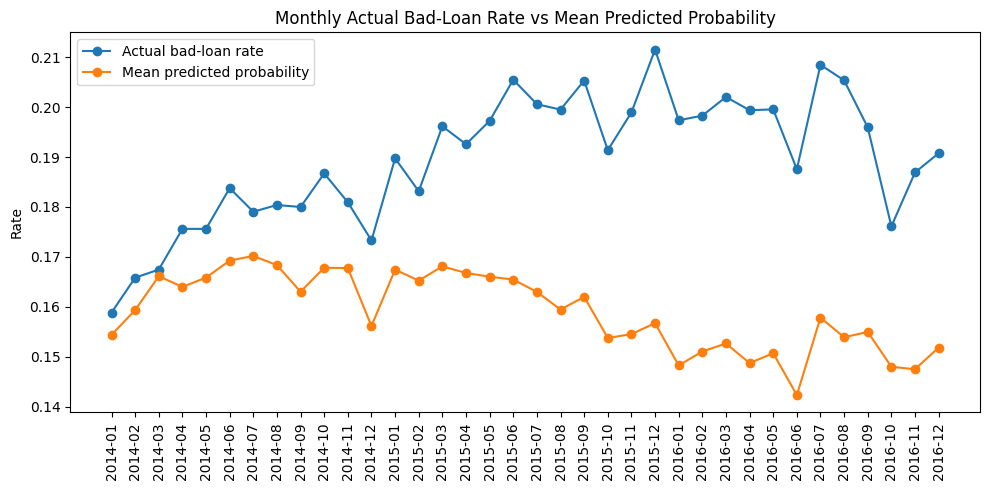

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_counts["monitor_month"], monthly_counts["actual_bad_loan_rate"], marker="o", label="Actual bad-loan rate")
plt.plot(monthly_counts["monitor_month"], monthly_counts["mean_predicted_probability"], marker="o", label="Mean predicted probability")
plt.xticks(rotation=90)
plt.ylabel("Rate")
plt.title("Monthly Actual Bad-Loan Rate vs Mean Predicted Probability")
plt.legend()
plt.tight_layout()
plt.show()

The mean predicted probability stays more or less flat while the realised bad-loan rate climbs away from it. Everything that follows is an attempt to detect that gap using signals available at different times.

## 3. Monthly Feature Drift Detection

Each monthly batch is compared with the 2013 reference distribution using Population Stability Index (PSI), which is the usual choice in credit-risk monitoring and is easy to read in a scorecard setting. The bands used are operational severity levels rather than statistical cut-offs:

- PSI < 0.10: low
- 0.10 ≤ PSI < 0.25: moderate
- PSI ≥ 0.25: high

PSI on its own has no notion of sample size, so a chi-square homogeneity test is run alongside it and the p-values are adjusted within each month using Benjamini–Hochberg. A feature only counts as supported drift when it has at least moderate PSI and an adjusted p-value below 0.05. This keeps the dashboard view separate from the stricter governance signal.

The monthly governance trigger fires when either one high-severity feature is statistically supported, or at least five features show supported drift in the same month. A single feature moving slightly should not count as a governance event, but a broad pattern should.

In [11]:
# Calculate PSI from reference and current bin counts
def calculate_psi_from_counts(reference_counts, current_counts, epsilon=1e-6):
    reference = np.asarray(reference_counts, dtype=float)
    current = np.asarray(current_counts, dtype=float)

    if reference.sum() == 0 or current.sum() == 0:
        return np.nan

    reference = reference / reference.sum()
    current = current / current.sum()

    reference = np.where(reference == 0, epsilon, reference)
    current = np.where(current == 0, epsilon, current)

    reference = reference / reference.sum()
    current = current / current.sum()

    psi = np.sum((current - reference) * np.log(current / reference))
    return psi

In [12]:
# Classify PSI using the selected thresholds
def classify_psi(psi_value):
    if pd.isna(psi_value):
        return "missing"
    elif psi_value >= 0.25:
        return "high"
    elif psi_value >= 0.10:
        return "moderate"
    else:
        return "low"

In [13]:
# Test whether reference and current distributions differ
def chi_square_drift_p_value(reference_counts, current_counts):
    table = np.vstack([np.asarray(reference_counts, dtype=float),
                       np.asarray(current_counts, dtype=float)])

    # Drop bins empty in both
    keep_cols = table.sum(axis=0) > 0
    table = table[:, keep_cols]

    if table.shape[1] < 2:
        return np.nan

    if table[0].sum() == 0 or table[1].sum() == 0:
        return np.nan

    try:
        _, p_value, _, _ = chi2_contingency(table, correction=False)
        return p_value
    except ValueError:
        return np.nan

In [14]:
# Adjust p-values for multiple feature tests
def benjamini_hochberg_adjustment(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full_like(p_values, np.nan, dtype=float)

    valid_mask = ~np.isnan(p_values)
    valid_p = p_values[valid_mask]

    if len(valid_p) == 0:
        return adjusted

    n_tests = len(valid_p)
    order = np.argsort(valid_p)
    ranked_p = valid_p[order]

    adjusted_ranked = ranked_p * n_tests / np.arange(1, n_tests + 1)
    adjusted_ranked = np.minimum.accumulate(adjusted_ranked[::-1])[::-1]
    adjusted_ranked = np.clip(adjusted_ranked, 0, 1)

    adjusted_valid = np.empty(n_tests)
    adjusted_valid[order] = adjusted_ranked

    adjusted[valid_mask] = adjusted_valid
    return adjusted

In [15]:
# Calculate PSI and chi-square drift for numeric features
def numeric_feature_drift(reference_df, current_df, feature, bin_edges):
    reference_values = pd.to_numeric(reference_df[feature], errors="coerce").dropna()
    current_values = pd.to_numeric(current_df[feature], errors="coerce").dropna()

    if len(reference_values) == 0 or len(current_values) == 0:
        return {"psi": np.nan,
                "p_value": np.nan}

    safe_edges = np.asarray(bin_edges, dtype=float).copy()
    safe_edges[0] = -np.inf
    safe_edges[-1] = np.inf

    reference_counts, _ = np.histogram(reference_values, bins=safe_edges)
    current_counts, _ = np.histogram(current_values, bins=safe_edges)

    psi_value = calculate_psi_from_counts(reference_counts, current_counts)
    p_value = chi_square_drift_p_value(reference_counts, current_counts)

    return {"psi": psi_value,
            "p_value": p_value}


In [16]:
# Prepare missing values as a separate category
def prepare_discrete_values(series):
    return (series.astype("object")
        .where(series.notna(), "__MISSING__")
        .astype(str))

In [17]:
# Calculate drift across discrete categories
def discrete_feature_drift(reference_df, current_df, feature):
    reference_values = prepare_discrete_values(reference_df[feature])
    current_values = prepare_discrete_values(current_df[feature])

    reference_counts_series = reference_values.value_counts(dropna=False)
    current_counts_series = current_values.value_counts(dropna=False)

    # Use every category found in either sample
    all_categories = sorted(set(reference_counts_series.index).union(
                            set(current_counts_series.index)))

    reference_counts = reference_counts_series.reindex(all_categories, fill_value=0).values
    current_counts = current_counts_series.reindex(all_categories, fill_value=0).values

    psi_value = calculate_psi_from_counts(reference_counts, current_counts)
    p_value = chi_square_drift_p_value(reference_counts, current_counts)

    return {"psi": psi_value,"p_value": p_value}

In [18]:
# Use the 2013 historical population as the feature reference
feature_reference_df = historical_df[monitoring_feature_cols].copy()

print("Feature reference shape:", feature_reference_df.shape)

Feature reference shape: (134814, 67)


In [19]:
# Calculate feature drift for each monitoring month
feature_drift_rows = []

for month, month_df in simulation_df.groupby("monitor_month"):
    for feature in numeric_psi_cols:
        drift_result = numeric_feature_drift(feature_reference_df,
                                             month_df,
                                             feature,
                                             numeric_bin_edges[feature])

        feature_drift_rows.append({"monitor_month": month,
                                   "feature": feature,
                                   "feature_type": "numeric",
                                   "psi": drift_result["psi"],
                                   "p_value": drift_result["p_value"],
                                   "drift_level": classify_psi(drift_result["psi"])})

    for feature in discrete_monitoring_cols:
        drift_result = discrete_feature_drift(feature_reference_df,
                                              month_df,
                                              feature)

        feature_drift_rows.append({"monitor_month": month,
                                   "feature": feature,
                                   "feature_type": "discrete",
                                   "psi": drift_result["psi"],
                                   "p_value": drift_result["p_value"],
                                   "drift_level": classify_psi(drift_result["psi"])})

feature_drift_long = pd.DataFrame(feature_drift_rows)

print("Feature-drift rows:", len(feature_drift_long))
display(feature_drift_long.head(20).round(4))

Feature-drift rows: 2412


,monitor_month,feature,feature_type,psi,p_value,drift_level
0,2014-01,loan_amnt,numeric,0.0198,0.0000,low
1,2014-01,installment,numeric,0.0122,0.0000,low
2,2014-01,emp_length,numeric,0.0033,0.0000,low
3,2014-01,annual_inc,numeric,0.0048,0.0000,low
4,2014-01,dti,numeric,0.0023,0.0003,low
5,2014-01,delinq_2yrs,numeric,0.0099,0.0000,low
6,2014-01,inq_last_6mths,numeric,0.0014,0.0000,low
7,2014-01,mths_since_last_delinq,numeric,0.0249,0.0000,low
8,2014-01,open_acc,numeric,0.0085,0.0000,low
9,2014-01,pub_rec,numeric,0.0383,0.0000,low


In [20]:
# Adjust p-values within each month, then combine effect size with significance
adjusted_p_values = (feature_drift_long.groupby("monitor_month", group_keys=False)
    .apply(lambda group: pd.Series(benjamini_hochberg_adjustment(group["p_value"].values),
                                   index=group.index)))

feature_drift_long["p_value_adj"] = adjusted_p_values
feature_drift_long["effect_size_drift"] = feature_drift_long["psi"] >= 0.10
feature_drift_long["statistically_supported"] = feature_drift_long["p_value_adj"] < 0.05
feature_drift_long["supported_feature_drift"] = (feature_drift_long["effect_size_drift"] &
                                                  feature_drift_long["statistically_supported"])
feature_drift_long["supported_moderate_drift"] = ((feature_drift_long["drift_level"] == "moderate") &
                                                   feature_drift_long["supported_feature_drift"])
feature_drift_long["supported_high_drift"] = ((feature_drift_long["drift_level"] == "high") &
                                               feature_drift_long["supported_feature_drift"])

display(feature_drift_long.head(10))

,monitor_month,feature,feature_type,psi,p_value,drift_level,p_value_adj,effect_size_drift,statistically_supported,supported_feature_drift,supported_moderate_drift,supported_high_drift
0,2014-01,loan_amnt,numeric,0.019753,3.556940e-54,low,1.401853e-53,False,True,False,False,False
1,2014-01,installment,numeric,0.012179,3.357517e-32,low,8.652062e-32,False,True,False,False,False
2,2014-01,emp_length,numeric,0.003320,4.920011e-08,low,7.166102e-08,False,True,False,False,False
3,2014-01,annual_inc,numeric,0.004842,4.584466e-11,low,7.313315e-11,False,True,False,False,False
4,2014-01,dti,numeric,0.002260,2.757588e-04,low,3.421452e-04,False,True,False,False,False
5,2014-01,delinq_2yrs,numeric,0.009923,4.234258e-34,low,1.134781e-33,False,True,False,False,False
6,2014-01,inq_last_6mths,numeric,0.001412,4.480423e-05,low,5.886046e-05,False,True,False,False,False
7,2014-01,mths_since_last_delinq,numeric,0.024925,1.384614e-76,low,8.433556e-76,False,True,False,False,False
8,2014-01,open_acc,numeric,0.008519,6.892198e-22,low,1.358168e-21,False,True,False,False,False
9,2014-01,pub_rec,numeric,0.038328,6.917759e-138,low,1.158725e-136,False,True,False,False,False


In [21]:
monthly_feature_drift_summary = (feature_drift_long.groupby("monitor_month")
    .agg(max_feature_psi=("psi", "max"),
         mean_feature_psi=("psi", "mean"),
         moderate_feature_drift_count=("drift_level", lambda x: (x == "moderate").sum()),
         high_feature_drift_count=("drift_level", lambda x: (x == "high").sum()),
         supported_moderate_drift_count=("supported_moderate_drift", "sum"),
         supported_high_drift_count=("supported_high_drift", "sum"),
         supported_feature_drift_count=("supported_feature_drift", "sum"))
    .reset_index())

# Dashboard view: PSI severity only
monthly_feature_drift_summary["feature_drift_dashboard_trigger"] = ((monthly_feature_drift_summary["max_feature_psi"] >= 0.25) |
                                                                     (monthly_feature_drift_summary["moderate_feature_drift_count"] >= 5))

# Governance view: PSI severity plus statistical support
monthly_feature_drift_summary["feature_drift_trigger"] = ((monthly_feature_drift_summary["supported_high_drift_count"] >= 1) |
                                                           (monthly_feature_drift_summary["supported_feature_drift_count"] >= 5))

display(monthly_feature_drift_summary.head(12))
display(monthly_feature_drift_summary.tail(12))

,monitor_month,max_feature_psi,mean_feature_psi,moderate_feature_drift_count,high_feature_drift_count,supported_moderate_drift_count,supported_high_drift_count,supported_feature_drift_count,feature_drift_dashboard_trigger,feature_drift_trigger
0,2014-01,0.166624,0.015199,1,0,1,0,1,False,False
1,2014-02,0.152764,0.015358,2,0,2,0,2,False,False
2,2014-03,0.365397,0.025158,2,2,2,2,4,True,True
3,2014-04,0.305656,0.024831,2,2,2,2,4,True,True
4,2014-05,0.329103,0.024753,2,2,2,2,4,True,True
5,2014-06,0.578082,0.027714,1,2,1,2,3,True,True
6,2014-07,0.509837,0.027314,2,2,2,2,4,True,True
7,2014-08,0.274629,0.022961,1,2,1,2,3,True,True
8,2014-09,0.236999,0.025469,3,0,3,0,3,False,False
9,2014-10,0.425534,0.029581,1,2,1,2,3,True,True


,monitor_month,max_feature_psi,mean_feature_psi,moderate_feature_drift_count,high_feature_drift_count,supported_moderate_drift_count,supported_high_drift_count,supported_feature_drift_count,feature_drift_dashboard_trigger,feature_drift_trigger
24,2016-01,1.064049,0.054297,4,1,4,1,5,True,True
25,2016-02,1.680162,0.059516,3,1,3,1,4,True,True
26,2016-03,1.718533,0.064631,6,2,6,2,8,True,True
27,2016-04,1.170915,0.060783,7,2,7,2,9,True,True
28,2016-05,0.938917,0.058189,7,2,7,2,9,True,True
29,2016-06,1.026751,0.058031,8,1,8,1,9,True,True
30,2016-07,0.894717,0.056994,8,1,8,1,9,True,True
31,2016-08,1.065882,0.054798,6,1,6,1,7,True,True
32,2016-09,0.617922,0.053227,7,2,7,2,9,True,True
33,2016-10,0.783072,0.056746,8,1,8,1,9,True,True


### Feature-drift sensitivity: platform-policy feature

`initial_list_status` records the loan listing format rather than borrower risk and produced the
largest PSI values in the monitored feature set. As a sensitivity check, the feature-drift trigger
is therefore recomputed without this variable to assess how strongly the feature-drift-only
baseline depends on this operational feature.

The primary analysis continues to use `feature_drift_trigger` with all champion inputs.
`feature_drift_trigger_excl_policy` is retained as a sensitivity result only.

In [22]:
# Sensitivity without the platform-policy feature
platform_policy_features = ["initial_list_status"]

feature_drift_excl_policy = feature_drift_long[~feature_drift_long["feature"].isin(platform_policy_features)].copy()

In [23]:
# Rebuild the monthly summary using the reduced feature set
monthly_feature_drift_summary_excl_policy = (feature_drift_excl_policy.groupby("monitor_month")
    .agg(max_feature_psi_excl_policy=("psi", "max"),
         mean_feature_psi_excl_policy=("psi", "mean"),
         supported_moderate_drift_count_excl_policy=("supported_moderate_drift", "sum"),
         supported_high_drift_count_excl_policy=("supported_high_drift", "sum"),
         supported_feature_drift_count_excl_policy=("supported_feature_drift", "sum"))
    .reset_index())

# Apply the same governance rule
monthly_feature_drift_summary_excl_policy["feature_drift_trigger_excl_policy"] = (
    (monthly_feature_drift_summary_excl_policy["supported_high_drift_count_excl_policy"] >= 1) |
    (monthly_feature_drift_summary_excl_policy["supported_feature_drift_count_excl_policy"] >= 5))

In [24]:
# Add the sensitivity trigger to the main summary
monthly_feature_drift_summary = (monthly_feature_drift_summary
    .drop(columns=["feature_drift_trigger_excl_policy"], errors="ignore")
    .merge(monthly_feature_drift_summary_excl_policy[["monitor_month", "feature_drift_trigger_excl_policy"]], 
           on="monitor_month",how="left"))

print("Excluded platform-policy features:", platform_policy_features)

print("Feature-drift trigger months (all monitored features):",int(monthly_feature_drift_summary["feature_drift_trigger"].sum()), "of",
      monthly_feature_drift_summary.shape[0])

print("Feature-drift trigger months (excluding platform-policy features):", int(monthly_feature_drift_summary["feature_drift_trigger_excl_policy"].sum()), "of",
      monthly_feature_drift_summary.shape[0])

display(monthly_feature_drift_summary_excl_policy.head(12).round(4))

Excluded platform-policy features: ['initial_list_status']
Feature-drift trigger months (all monitored features): 33 of 36
Feature-drift trigger months (excluding platform-policy features): 27 of 36


,monitor_month,max_feature_psi_excl_policy,mean_feature_psi_excl_policy,supported_moderate_drift_count_excl_policy,supported_high_drift_count_excl_policy,supported_feature_drift_count_excl_policy,feature_drift_trigger_excl_policy
0,2014-01,0.1666,0.0152,1,0,1,False
1,2014-02,0.1528,0.0151,2,0,2,False
2,2014-03,0.3654,0.0239,1,2,3,True
3,2014-04,0.2541,0.0206,2,1,3,True
4,2014-05,0.2640,0.0201,2,1,3,True
5,2014-06,0.3538,0.0194,1,1,2,True
6,2014-07,0.3426,0.0200,2,1,3,True
7,2014-08,0.2746,0.0194,1,1,2,True
8,2014-09,0.2370,0.0237,2,0,2,False
9,2014-10,0.2589,0.0236,1,1,2,True


In [25]:
# Which features drift most often across the whole period
top_drifting_features = (feature_drift_long.groupby("feature")
    .agg(max_psi=("psi", "max"),
         mean_psi=("psi", "mean"),
         moderate_months=("drift_level", lambda x: (x == "moderate").sum()),
         high_months=("drift_level", lambda x: (x == "high").sum()),
         supported_months=("supported_feature_drift", "sum"),
         supported_high_months=("supported_high_drift", "sum"),
         min_adjusted_p_value=("p_value_adj", "min"))
    .reset_index()
    .sort_values("max_psi", ascending=False))

display(top_drifting_features.head(20).round(4))

,feature,max_psi,mean_psi,moderate_months,high_months,supported_months,supported_high_months,min_adjusted_p_value
16,initial_list_status,1.7185,0.6335,5,29,34,29,0.0
66,verification_status,0.3778,0.2556,14,21,35,21,0.0
43,num_tl_120dpd_2m_missing,0.3169,0.1274,18,2,20,2,0.0
55,revol_util,0.2010,0.0745,11,0,11,0,0.0
58,tot_coll_amt,0.1912,0.1396,36,0,36,0,0.0
49,percent_bc_gt_75,0.1832,0.0639,10,0,10,0,0.0
56,sub_grade,0.1827,0.0792,7,0,7,0,0.0
36,num_bc_tl,0.1685,0.0645,9,0,9,0,0.0
6,bc_util,0.1647,0.0571,9,0,9,0,0.0
18,installment,0.1147,0.0313,4,0,4,0,0.0


,monitor_month,initial_list_status,count,proportion
0,2014-01,0,10613,0.679102
1,2014-01,1,5015,0.320898
2,2014-02,0,9874,0.646670
3,2014-02,1,5395,0.353330
4,2014-03,0,9570,0.579543
5,2014-03,1,6943,0.420457
6,2014-04,0,8903,0.466834
7,2014-04,1,10168,0.533166
8,2014-05,0,8718,0.456464
9,2014-05,1,10381,0.543536


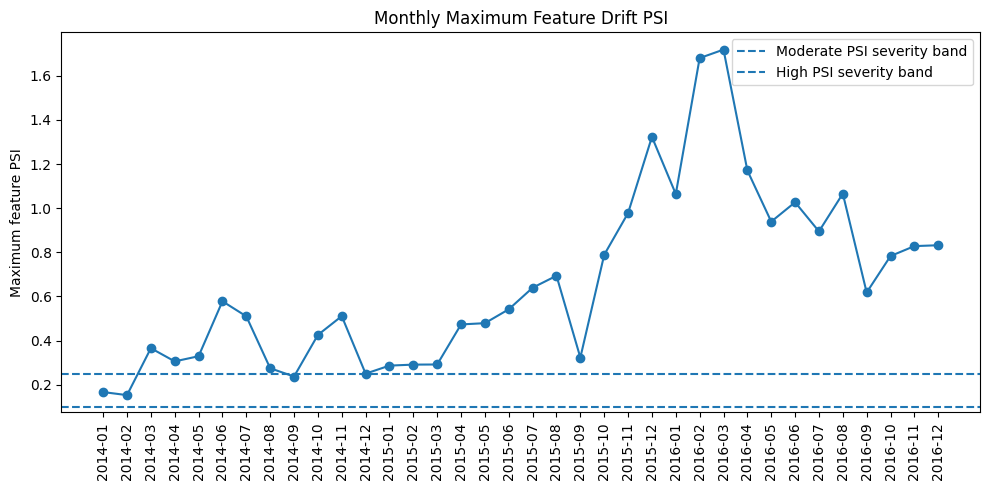

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_feature_drift_summary["monitor_month"], monthly_feature_drift_summary["max_feature_psi"], marker="o")
initial_status_monthly = (simulation_df.groupby(["monitor_month", "initial_list_status"]).size().rename("count").reset_index())

initial_status_monthly["proportion"] = (initial_status_monthly["count"] /
                                        initial_status_monthly.groupby("monitor_month")["count"].transform("sum"))

display(initial_status_monthly.head(20))
plt.axhline(0.10, linestyle="--", label="Moderate PSI severity band")
plt.axhline(0.25, linestyle="--", label="High PSI severity band")
plt.xticks(rotation=90)
plt.ylabel("Maximum feature PSI")
plt.title("Monthly Maximum Feature Drift PSI")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
# Track the platform listing field separately from borrower-risk features
initial_status_monthly = (simulation_df.groupby(["monitor_month", "initial_list_status"])
    .size()
    .rename("count")
    .reset_index())

initial_status_monthly["proportion"] = (initial_status_monthly["count"] /
                                        initial_status_monthly.groupby("monitor_month")["count"].transform("sum"))

display(initial_status_monthly.head(20))

,monitor_month,initial_list_status,count,proportion
0,2014-01,0,10613,0.679102
1,2014-01,1,5015,0.320898
2,2014-02,0,9874,0.646670
3,2014-02,1,5395,0.353330
4,2014-03,0,9570,0.579543
5,2014-03,1,6943,0.420457
6,2014-04,0,8903,0.466834
7,2014-04,1,10168,0.533166
8,2014-05,0,8718,0.456464
9,2014-05,1,10381,0.543536


In [28]:
# Its 2013 reference share, for comparison with the monthly shares above
reference_initial_status = (historical_df["initial_list_status"]
    .value_counts(normalize=True)
    .rename("reference_proportion")
    .reset_index())

reference_initial_status.columns = ["initial_list_status", "reference_proportion"]

display(reference_initial_status)

,initial_list_status,reference_proportion
0,0,0.733596
1,1,0.266404


Feature drift alerted in 33 of the 36 months. That is early-warning evidence of input movement, not a reason to retrain: in the multi-signal policy it only matters once delayed outcome evidence agrees with it.

## 4. Monthly Prediction Drift Detection

Monthly predicted-probability distributions are compared with the November–December 2013
calibration reference using Jensen–Shannon divergence (JSD).

Two different questions are reported. Statistical detectability asks whether the month moved more than sampling noise, using an empirical null from resampling the calibration scores. Operational materiality asks whether the movement is big enough to act on, using fixed JSD bands of 0.01 and 0.03.

Only the operational band feeds the policy. With monthly samples this large, almost any movement is statistically detectable, so using the null as the trigger would fire constantly. Prediction drift stays an early-warning diagnostic and cannot trigger retraining alone.

In [29]:
# Fixed JSD materiality bands
prediction_jsd_moderate_band = 0.01
prediction_jsd_high_band = 0.03

In [30]:
# Calculate Jensen-Shannon divergence between binned score distributions
def calculate_jsd_from_counts(reference_counts, current_counts, epsilon=1e-12):
    reference = np.asarray(reference_counts, dtype=float) + epsilon
    current = np.asarray(current_counts, dtype=float) + epsilon

    reference = reference / reference.sum()
    current = current / current.sum()
    midpoint = 0.5 * (reference + current)

    kl_reference = np.sum(reference * np.log(reference / midpoint))
    kl_current = np.sum(current * np.log(current / midpoint))

    return 0.5 * (kl_reference + kl_current)

In [31]:
# Count scores using the calibration-period bins
def get_binned_counts(scores, score_edges):
    scores = pd.Series(scores).dropna()
    counts, _ = np.histogram(scores, bins=score_edges)

    return counts

In [32]:
# Simulate JSD values expected from sampling noise
def empirical_null_jsd(reference_proportions, reference_n, current_n, n_simulations=2000, seed=42):
    rng = np.random.default_rng(seed)
    reference_proportions = np.asarray(reference_proportions, dtype=float)
    reference_proportions = reference_proportions / reference_proportions.sum()

    null_jsd_values = np.empty(n_simulations)

    for i in range(n_simulations):
        simulated_reference_counts = rng.multinomial(reference_n, reference_proportions)
        simulated_current_counts = rng.multinomial(current_n, reference_proportions)
        null_jsd_values[i] = calculate_jsd_from_counts(simulated_reference_counts,
                                                        simulated_current_counts)

    return null_jsd_values

In [33]:
# Classify prediction drift using the fixed JSD bands
def classify_prediction_drift_level(jsd_value):
    if pd.isna(jsd_value):
        return "missing"
    elif jsd_value >= prediction_jsd_high_band:
        return "high"
    elif jsd_value >= prediction_jsd_moderate_band:
        return "moderate"
    else:
        return "low"

In [34]:
# Classify JSD against the empirical null thresholds
def classify_empirical_jsd(row):
    if pd.isna(row["prediction_jsd"]):
        return "missing"
    elif row["prediction_jsd"] >= row["jsd_null_p99"]:
        return "high"
    elif row["prediction_jsd"] >= row["jsd_null_p95"]:
        return "moderate"
    else:
        return "low"

In [35]:
reference_counts = prediction_drift_baseline["reference_count"].values
reference_proportions = prediction_drift_baseline["reference_proportion"].values
reference_n = int(reference_counts.sum())

# Keep the outer bins open for later scores
print("Score edges:", score_edges[0], "...", score_edges[-1])
assert np.isneginf(score_edges[0]), "Lower score edge is not open-ended."
assert np.isposinf(score_edges[-1]), "Upper score edge is not open-ended."

Score edges: -inf ... inf


In [36]:
# Calculate prediction drift for each monitoring month
prediction_drift_rows = []

for month, month_df in simulation_df.groupby("monitor_month"):
    current_scores = month_df[prediction_col]
    current_counts = get_binned_counts(current_scores, score_edges)

    assert current_counts.sum() == len(month_df), f"{month}: binned {current_counts.sum()} scores but expected {len(month_df)}"

    prediction_jsd = calculate_jsd_from_counts(reference_counts, current_counts)

    null_jsd_values = empirical_null_jsd(reference_proportions=reference_proportions,
                                         reference_n=reference_n,
                                         current_n=int(current_counts.sum()),
                                         n_simulations=2000,
                                         seed=42)

    prediction_drift_rows.append({"monitor_month": month,
                                  "rows": len(month_df),
                                  "mean_predicted_probability": current_scores.mean(),
                                  "prediction_jsd": prediction_jsd,
                                  "jsd_null_p95": np.quantile(null_jsd_values, 0.95),
                                  "jsd_null_p99": np.quantile(null_jsd_values, 0.99),
                                  "jsd_null_p_value": (1 + np.sum(null_jsd_values >= prediction_jsd)) /
                                                      (len(null_jsd_values) + 1)})

monthly_prediction_drift = pd.DataFrame(prediction_drift_rows)

print("Prediction score-bin checks passed.")

Prediction score-bin checks passed.


In [37]:
# Add statistical and operational prediction-drift indicators
monthly_prediction_drift["prediction_drift_level"] = monthly_prediction_drift["prediction_jsd"].apply(classify_prediction_drift_level)
monthly_prediction_drift["prediction_jsd_empirical_level"] = monthly_prediction_drift.apply(classify_empirical_jsd, axis=1)

monthly_prediction_drift["prediction_jsd_exceeds_null_p95"] = (monthly_prediction_drift["prediction_jsd"] >=
                                                               monthly_prediction_drift["jsd_null_p95"])
monthly_prediction_drift["prediction_jsd_exceeds_null_p99"] = (monthly_prediction_drift["prediction_jsd"] >=
                                                               monthly_prediction_drift["jsd_null_p99"])

# Trigger used by the multi-signal policy
monthly_prediction_drift["prediction_drift_trigger"] = monthly_prediction_drift["prediction_jsd"] >= prediction_jsd_moderate_band

monthly_prediction_drift["jsd_to_null_p99_ratio"] = (monthly_prediction_drift["prediction_jsd"] / monthly_prediction_drift["jsd_null_p99"])
monthly_prediction_drift["jsd_to_material_band_ratio"] = (monthly_prediction_drift["prediction_jsd"] / prediction_jsd_moderate_band)

In [38]:
# Check how many months trigger under alternative JSD bands
for band in [0.005, 0.0075, 0.01, 0.02, 0.03]:
    triggered_months = int((monthly_prediction_drift["prediction_jsd"] >= band).sum())
    print(f"Band {band}: {triggered_months}/36 months trigger")

print("\nStatistical vs operational summary")
print("Months exceeding null p99:", int(monthly_prediction_drift["prediction_jsd_exceeds_null_p99"].sum()), "/ 36")
print("Months reaching JSD >= 0.01:", int(monthly_prediction_drift["prediction_drift_trigger"].sum()), "/ 36")
print("Max observed JSD:", round(monthly_prediction_drift["prediction_jsd"].max(), 5))
print("Median observed/null-p99 ratio:", round(monthly_prediction_drift["jsd_to_null_p99_ratio"].median(), 1))
print("Max observed as fraction of material band:", round(monthly_prediction_drift["jsd_to_material_band_ratio"].max(), 3))

display(monthly_prediction_drift.head(12).round(5))
display(monthly_prediction_drift.iloc[12:24].round(5))
display(monthly_prediction_drift.tail(12).round(5))

Band 0.005: 0/36 months trigger
Band 0.0075: 0/36 months trigger
Band 0.01: 0/36 months trigger
Band 0.02: 0/36 months trigger
Band 0.03: 0/36 months trigger

Statistical vs operational summary
Months exceeding null p99: 36 / 36
Months reaching JSD >= 0.01: 0 / 36
Max observed JSD: 0.00471
Median observed/null-p99 ratio: 12.6
Max observed as fraction of material band: 0.471


,monitor_month,rows,mean_predicted_probability,prediction_jsd,jsd_null_p95,jsd_null_p99,jsd_null_p_value,prediction_drift_level,prediction_jsd_empirical_level,prediction_jsd_exceeds_null_p95,prediction_jsd_exceeds_null_p99,prediction_drift_trigger,jsd_to_null_p99_ratio,jsd_to_material_band_ratio
0,2014-01,15628,0.15436,0.00056,0.00021,0.00027,0.0005,low,high,True,True,False,2.08552,0.05571
1,2014-02,15269,0.15934,0.00124,0.00021,0.00027,0.0005,low,high,True,True,False,4.67885,0.12419
2,2014-03,16513,0.16611,0.00331,0.00020,0.00025,0.0005,low,high,True,True,False,13.15620,0.33094
3,2014-04,19071,0.16398,0.00242,0.00019,0.00022,0.0005,low,high,True,True,False,10.75271,0.24170
4,2014-05,19099,0.16583,0.00320,0.00018,0.00025,0.0005,low,high,True,True,False,12.71503,0.32000
5,2014-06,17179,0.16925,0.00452,0.00020,0.00025,0.0005,low,high,True,True,False,18.15636,0.45196
6,2014-07,29306,0.17019,0.00471,0.00014,0.00019,0.0005,low,high,True,True,False,24.77610,0.47054
7,2014-08,18814,0.16834,0.00437,0.00018,0.00023,0.0005,low,high,True,True,False,18.71953,0.43735
8,2014-09,10606,0.16301,0.00467,0.00028,0.00035,0.0005,low,high,True,True,False,13.34859,0.46686
9,2014-10,38781,0.16782,0.00408,0.00012,0.00017,0.0005,low,high,True,True,False,24.62376,0.40769


,monitor_month,rows,mean_predicted_probability,prediction_jsd,jsd_null_p95,jsd_null_p99,jsd_null_p_value,prediction_drift_level,prediction_jsd_empirical_level,prediction_jsd_exceeds_null_p95,prediction_jsd_exceeds_null_p99,prediction_drift_trigger,jsd_to_null_p99_ratio,jsd_to_material_band_ratio
12,2015-01,35080,0.16743,0.00344,0.00014,0.00017,0.0005,low,high,True,True,False,20.22151,0.34413
13,2015-02,23734,0.16524,0.00268,0.00016,0.00020,0.0005,low,high,True,True,False,13.48098,0.26845
14,2015-03,25361,0.16810,0.00334,0.00015,0.00020,0.0005,low,high,True,True,False,16.97211,0.33432
15,2015-04,35259,0.16677,0.00307,0.00013,0.00018,0.0005,low,high,True,True,False,17.40285,0.30655
16,2015-05,31174,0.16602,0.00357,0.00014,0.00018,0.0005,low,high,True,True,False,19.70794,0.35658
17,2015-06,27001,0.16546,0.00340,0.00015,0.00019,0.0005,low,high,True,True,False,17.85362,0.33958
18,2015-07,43415,0.16297,0.00232,0.00012,0.00016,0.0005,low,high,True,True,False,14.73676,0.23249
19,2015-08,33552,0.15944,0.00167,0.00013,0.00017,0.0005,low,high,True,True,False,9.89851,0.16678
20,2015-09,26687,0.16198,0.00242,0.00015,0.00019,0.0005,low,high,True,True,False,13.04969,0.24195
21,2015-10,45444,0.15374,0.00086,0.00012,0.00016,0.0005,low,high,True,True,False,5.53031,0.08585


,monitor_month,rows,mean_predicted_probability,prediction_jsd,jsd_null_p95,jsd_null_p99,jsd_null_p_value,prediction_drift_level,prediction_jsd_empirical_level,prediction_jsd_exceeds_null_p95,prediction_jsd_exceeds_null_p99,prediction_drift_trigger,jsd_to_null_p99_ratio,jsd_to_material_band_ratio
24,2016-01,30161,0.14824,0.00224,0.00014,0.00018,0.0005,low,high,True,True,False,12.58453,0.22382
25,2016-02,36788,0.15103,0.00097,0.00013,0.00017,0.0005,low,high,True,True,False,5.61861,0.09653
26,2016-03,57558,0.15264,0.00379,0.00011,0.00014,0.0005,low,high,True,True,False,26.68716,0.37925
27,2016-04,34164,0.14871,0.00389,0.00013,0.00017,0.0005,low,high,True,True,False,22.34352,0.38885
28,2016-05,26488,0.15069,0.00097,0.00015,0.00020,0.0005,low,high,True,True,False,4.92847,0.09667
29,2016-06,30582,0.14229,0.00176,0.00014,0.00018,0.0005,low,high,True,True,False,9.74398,0.17648
30,2016-07,32050,0.15783,0.00192,0.00014,0.00018,0.0005,low,high,True,True,False,10.78167,0.19240
31,2016-08,33641,0.15388,0.00123,0.00014,0.00017,0.0005,low,high,True,True,False,7.03963,0.12315
32,2016-09,26171,0.15496,0.00132,0.00015,0.00019,0.0005,low,high,True,True,False,6.81754,0.13190
33,2016-10,30305,0.14797,0.00105,0.00014,0.00018,0.0005,low,high,True,True,False,5.87562,0.10527


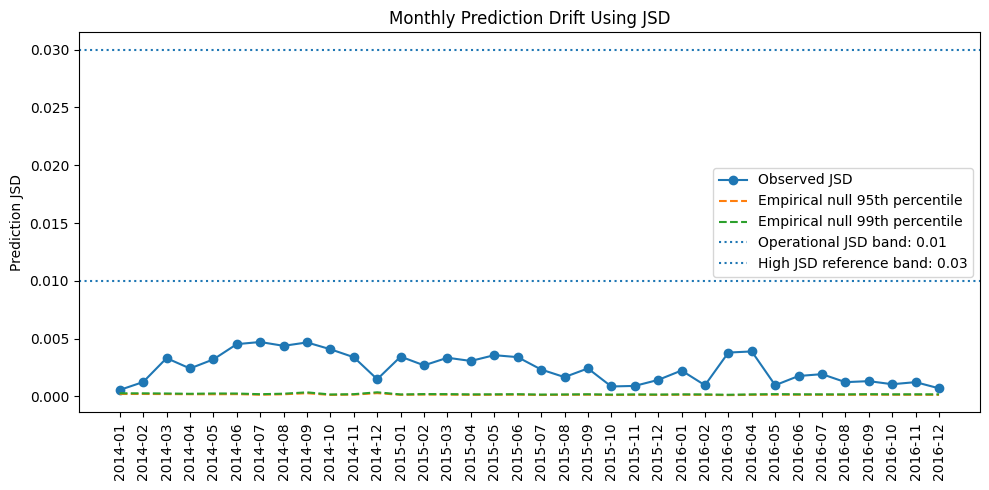

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_prediction_drift["monitor_month"], monthly_prediction_drift["prediction_jsd"],marker="o",label="Observed JSD")

plt.plot(monthly_prediction_drift["monitor_month"],monthly_prediction_drift["jsd_null_p95"],linestyle="--",label="Empirical null 95th percentile")

plt.plot(monthly_prediction_drift["monitor_month"],monthly_prediction_drift["jsd_null_p99"],linestyle="--",label="Empirical null 99th percentile")

plt.axhline(prediction_jsd_moderate_band, linestyle=":", label="Operational JSD band: 0.01")
plt.axhline(prediction_jsd_high_band, linestyle=":", label="High JSD reference band: 0.03")

plt.xticks(rotation=90)
plt.ylabel("Prediction JSD")
plt.title("Monthly Prediction Drift Using JSD")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# Headline prediction-drift numbers across all months
prediction_drift_check = pd.DataFrame([{"max_prediction_jsd": monthly_prediction_drift["prediction_jsd"].max(),
                                        "mean_prediction_jsd": monthly_prediction_drift["prediction_jsd"].mean(),
                                        "statistical_null_p99_months": monthly_prediction_drift["prediction_jsd_exceeds_null_p99"].sum(),
                                        "operational_triggered_months": monthly_prediction_drift["prediction_drift_trigger"].sum(),
                                        "empirical_high_months": (monthly_prediction_drift["prediction_jsd_empirical_level"] == "high").sum(),
                                        "empirical_moderate_months": (monthly_prediction_drift["prediction_jsd_empirical_level"] == "moderate").sum(),
                                        "max_jsd_to_material_band_ratio": monthly_prediction_drift["jsd_to_material_band_ratio"].max(),
                                        "median_jsd_to_null_p99_ratio": monthly_prediction_drift["jsd_to_null_p99_ratio"].median()}])

display(prediction_drift_check.round(5))

prediction_drift_level_counts = (monthly_prediction_drift[["prediction_drift_level",
                                                           "prediction_jsd_empirical_level",
                                                           "prediction_jsd_exceeds_null_p99",
                                                           "prediction_drift_trigger"]].value_counts().reset_index(name="months"))

display(prediction_drift_level_counts)

,max_prediction_jsd,mean_prediction_jsd,statistical_null_p99_months,operational_triggered_months,empirical_high_months,empirical_moderate_months,max_jsd_to_material_band_ratio,median_jsd_to_null_p99_ratio
0,0.00471,0.00245,36,0,36,0,0.47054,12.64978


,prediction_drift_level,prediction_jsd_empirical_level,prediction_jsd_exceeds_null_p99,prediction_drift_trigger,months
0,low,high,True,False,36


In [41]:
# Same picture aggregated by year
monthly_prediction_drift["monitor_year"] = monthly_prediction_drift["monitor_month"].str[:4]

yearly_prediction_drift_summary = (monthly_prediction_drift.groupby("monitor_year")
    .agg(months=("monitor_month", "count"),
         mean_prediction_jsd=("prediction_jsd", "mean"),
         max_prediction_jsd=("prediction_jsd", "max"),
         statistical_null_p99_months=("prediction_jsd_exceeds_null_p99", "sum"),
         operational_triggered_months=("prediction_drift_trigger", "sum"),
         empirical_high_months=("prediction_jsd_empirical_level", lambda x: (x == "high").sum()))
    .reset_index())

display(yearly_prediction_drift_summary.round(5))

,monitor_year,months,mean_prediction_jsd,max_prediction_jsd,statistical_null_p99_months,operational_triggered_months,empirical_high_months
0,2014,12,0.00316,0.00471,12,0,12
1,2015,12,0.00242,0.00357,12,0,12
2,2016,12,0.00176,0.00389,12,0,12


All 36 months were above the empirical null 99th percentile, but none reached the operational JSD threshold of 0.01. The highest JSD was 0.00471.
although the change in prediction distributions was statistically detectable, it remained small in practical terms. Prediction drift on its own did not give a strong enough signal to act on.

## 5. Delayed Target Drift Detection

Each month’s realised bad-loan rate is compared with the November–December 2013 baseline. Because labels are delayed by five months, each monitoring month is linked to the month when its outcomes become available.
The trigger is one-sided: it fires when the bad-loan rate rises by at least 2 percentage points above baseline, with a 4-point increase treated as high. Falls in the bad-loan rate are not treated as deterioration, so they do not trigger an alert.

In [42]:
# Compare realised bad-loan rates with the 2013 baseline
baseline_bad_loan_rate = float(concept_drift_baseline["actual_bad_loan_rate"].iloc[0])

monthly_target_drift = monthly_counts[["monitor_month", "rows", "actual_bad_loan_rate", "mean_predicted_probability", "calibration_gap"]].copy()

monthly_target_drift["baseline_bad_loan_rate"] = baseline_bad_loan_rate

In [43]:
# Add the simulated label delay
label_delay_months = 5

monthly_target_drift["label_delay_months"] = label_delay_months
monthly_target_drift["label_available_month"] = monthly_target_drift["monitor_month"].apply(
    lambda x: (pd.Period(x, freq="M") + label_delay_months).strftime("%Y-%m"))

In [44]:
# Measure change from the baseline bad-loan rate
monthly_target_drift["target_rate_change"] = (monthly_target_drift["actual_bad_loan_rate"] -
                                               monthly_target_drift["baseline_bad_loan_rate"])

monthly_target_drift["absolute_target_rate_change"] = monthly_target_drift["target_rate_change"].abs()

monthly_target_drift["target_rate_relative_change"] = (monthly_target_drift["target_rate_change"] /
                                                        monthly_target_drift["baseline_bad_loan_rate"])

target_moderate_threshold = 0.02
target_high_threshold = 0.04

In [45]:
# Classify increases in the bad-loan rate
def classify_target_drift(change):
    if pd.isna(change):
        return "missing"
    elif change >= target_high_threshold:
        return "high"
    elif change >= target_moderate_threshold:
        return "moderate"
    else:
        return "low"

In [46]:
# Describe the size and direction of each shift
def classify_target_shift_twosided(change):
    if pd.isna(change):
        return "missing"

    abs_change = abs(change)
    direction = "increase" if change > 0 else "decrease"

    if abs_change >= target_high_threshold:
        return f"high_{direction}"
    elif abs_change >= target_moderate_threshold:
        return f"moderate_{direction}"
    else:
        return "low"

In [47]:
# Apply the target-drift rules
monthly_target_drift["target_drift_level"] = monthly_target_drift["target_rate_change"].apply(classify_target_drift)
monthly_target_drift["target_shift_description"] = monthly_target_drift["target_rate_change"].apply(classify_target_shift_twosided)

# Trigger only when the bad-loan rate rises
monthly_target_drift["target_drift_trigger"] = monthly_target_drift["target_rate_change"] >= target_moderate_threshold

target_display_cols = ["monitor_month", "label_available_month", "label_delay_months", "rows",
                       "actual_bad_loan_rate", "mean_predicted_probability", "calibration_gap",
                       "baseline_bad_loan_rate", "target_rate_change", "absolute_target_rate_change",
                       "target_rate_relative_change", "target_drift_level", "target_shift_description",
                       "target_drift_trigger"]

display(monthly_target_drift[target_display_cols].head(12).round(4))
display(monthly_target_drift[target_display_cols].iloc[12:24].round(4))
display(monthly_target_drift[target_display_cols].tail(12).round(4))

,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,baseline_bad_loan_rate,target_rate_change,absolute_target_rate_change,target_rate_relative_change,target_drift_level,target_shift_description,target_drift_trigger
0,2014-01,2014-06,5,15628,0.1588,0.1544,0.0045,0.1536,0.0052,0.0052,0.0340,low,low,False
1,2014-02,2014-07,5,15269,0.1658,0.1593,0.0065,0.1536,0.0122,0.0122,0.0796,low,low,False
2,2014-03,2014-08,5,16513,0.1674,0.1661,0.0013,0.1536,0.0138,0.0138,0.0901,low,low,False
3,2014-04,2014-09,5,19071,0.1756,0.1640,0.0116,0.1536,0.0220,0.0220,0.1433,moderate,moderate_increase,True
4,2014-05,2014-10,5,19099,0.1756,0.1658,0.0098,0.1536,0.0220,0.0220,0.1433,moderate,moderate_increase,True
5,2014-06,2014-11,5,17179,0.1838,0.1693,0.0145,0.1536,0.0302,0.0302,0.1964,moderate,moderate_increase,True
6,2014-07,2014-12,5,29306,0.1790,0.1702,0.0089,0.1536,0.0254,0.0254,0.1657,moderate,moderate_increase,True
7,2014-08,2015-01,5,18814,0.1804,0.1683,0.0121,0.1536,0.0268,0.0268,0.1745,moderate,moderate_increase,True
8,2014-09,2015-02,5,10606,0.1800,0.1630,0.0170,0.1536,0.0264,0.0264,0.1718,moderate,moderate_increase,True
9,2014-10,2015-03,5,38781,0.1867,0.1678,0.0189,0.1536,0.0331,0.0331,0.2156,moderate,moderate_increase,True


,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,baseline_bad_loan_rate,target_rate_change,absolute_target_rate_change,target_rate_relative_change,target_drift_level,target_shift_description,target_drift_trigger
12,2015-01,2015-06,5,35080,0.1897,0.1674,0.0223,0.1536,0.0361,0.0361,0.2353,moderate,moderate_increase,True
13,2015-02,2015-07,5,23734,0.1832,0.1652,0.0179,0.1536,0.0296,0.0296,0.1924,moderate,moderate_increase,True
14,2015-03,2015-08,5,25361,0.1962,0.1681,0.0281,0.1536,0.0426,0.0426,0.2771,high,high_increase,True
15,2015-04,2015-09,5,35259,0.1926,0.1668,0.0258,0.1536,0.0390,0.0390,0.2538,moderate,moderate_increase,True
16,2015-05,2015-10,5,31174,0.1972,0.1660,0.0312,0.1536,0.0436,0.0436,0.2842,high,high_increase,True
17,2015-06,2015-11,5,27001,0.2055,0.1655,0.0401,0.1536,0.0519,0.0519,0.3380,high,high_increase,True
18,2015-07,2015-12,5,43415,0.2006,0.1630,0.0376,0.1536,0.0470,0.0470,0.3060,high,high_increase,True
19,2015-08,2016-01,5,33552,0.1995,0.1594,0.0401,0.1536,0.0459,0.0459,0.2989,high,high_increase,True
20,2015-09,2016-02,5,26687,0.2053,0.1620,0.0434,0.1536,0.0517,0.0517,0.3369,high,high_increase,True
21,2015-10,2016-03,5,45444,0.1914,0.1537,0.0376,0.1536,0.0378,0.0378,0.2460,moderate,moderate_increase,True


,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,baseline_bad_loan_rate,target_rate_change,absolute_target_rate_change,target_rate_relative_change,target_drift_level,target_shift_description,target_drift_trigger
24,2016-01,2016-06,5,30161,0.1974,0.1482,0.0491,0.1536,0.0438,0.0438,0.2850,high,high_increase,True
25,2016-02,2016-07,5,36788,0.1983,0.1510,0.0473,0.1536,0.0447,0.0447,0.2910,high,high_increase,True
26,2016-03,2016-08,5,57558,0.2020,0.1526,0.0494,0.1536,0.0484,0.0484,0.3154,high,high_increase,True
27,2016-04,2016-09,5,34164,0.1994,0.1487,0.0507,0.1536,0.0458,0.0458,0.2981,high,high_increase,True
28,2016-05,2016-10,5,26488,0.1996,0.1507,0.0489,0.1536,0.0460,0.0460,0.2993,high,high_increase,True
29,2016-06,2016-11,5,30582,0.1876,0.1423,0.0453,0.1536,0.0340,0.0340,0.2211,moderate,moderate_increase,True
30,2016-07,2016-12,5,32050,0.2085,0.1578,0.0507,0.1536,0.0549,0.0549,0.3574,high,high_increase,True
31,2016-08,2017-01,5,33641,0.2054,0.1539,0.0515,0.1536,0.0518,0.0518,0.3371,high,high_increase,True
32,2016-09,2017-02,5,26171,0.1959,0.1550,0.0410,0.1536,0.0423,0.0423,0.2757,high,high_increase,True
33,2016-10,2017-03,5,30305,0.1761,0.1480,0.0281,0.1536,0.0225,0.0225,0.1466,moderate,moderate_increase,True


In [48]:
# Headline target-drift numbers across all months
target_drift_check = pd.DataFrame([{"baseline_bad_loan_rate": baseline_bad_loan_rate,
                                    "max_actual_bad_loan_rate": monthly_target_drift["actual_bad_loan_rate"].max(),
                                    "mean_actual_bad_loan_rate": monthly_target_drift["actual_bad_loan_rate"].mean(),
                                    "max_target_rate_change": monthly_target_drift["target_rate_change"].max(),
                                    "max_absolute_target_rate_change": monthly_target_drift["absolute_target_rate_change"].max(),
                                    "mean_target_rate_change": monthly_target_drift["target_rate_change"].mean(),
                                    "triggered_months": monthly_target_drift["target_drift_trigger"].sum(),
                                    "moderate_months": (monthly_target_drift["target_drift_level"] == "moderate").sum(),
                                    "high_months": (monthly_target_drift["target_drift_level"] == "high").sum()}])

display(target_drift_check.round(4))

target_drift_level_counts = (monthly_target_drift[["target_drift_level", "target_shift_description", "target_drift_trigger"]]
    .value_counts().reset_index(name="months"))

display(target_drift_level_counts)

,baseline_bad_loan_rate,max_actual_bad_loan_rate,mean_actual_bad_loan_rate,max_target_rate_change,max_absolute_target_rate_change,mean_target_rate_change,triggered_months,moderate_months,high_months
0,0.1536,0.2115,0.1896,0.0579,0.0579,0.036,32,16,16


,target_drift_level,target_shift_description,target_drift_trigger,months
0,moderate,moderate_increase,True,16
1,high,high_increase,True,16
2,low,low,False,4


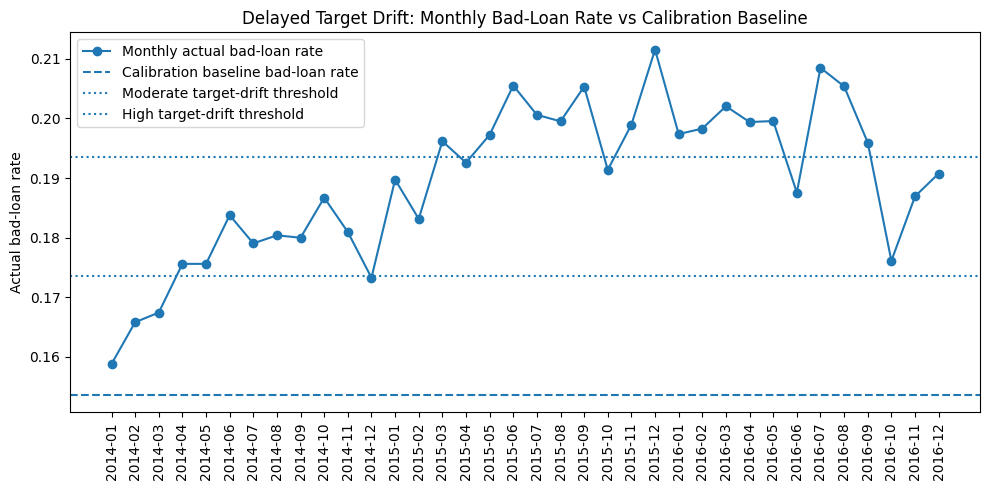

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_target_drift["monitor_month"],monthly_target_drift["actual_bad_loan_rate"], marker="o",
         label="Monthly actual bad-loan rate")

plt.axhline(baseline_bad_loan_rate, linestyle="--", label="Calibration baseline bad-loan rate")
plt.axhline(baseline_bad_loan_rate + target_moderate_threshold, linestyle=":", label="Moderate target-drift threshold")
plt.axhline(baseline_bad_loan_rate + target_high_threshold, linestyle=":", label="High target-drift threshold")
plt.xticks(rotation=90)
plt.ylabel("Actual bad-loan rate")
plt.title("Delayed Target Drift: Monthly Bad-Loan Rate vs Calibration Baseline")
plt.legend()
plt.tight_layout()
plt.show()

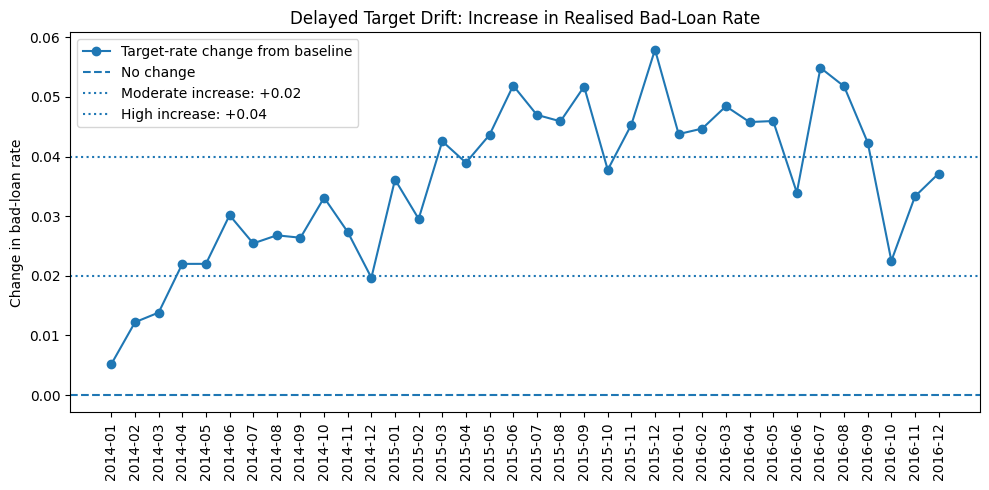

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_target_drift["monitor_month"], monthly_target_drift["target_rate_change"], marker="o",
    label="Target-rate change from baseline")

plt.axhline(0, linestyle="--", label="No change")
plt.axhline(target_moderate_threshold, linestyle=":", label="Moderate increase: +0.02")
plt.axhline(target_high_threshold, linestyle=":", label="High increase: +0.04")
plt.xticks(rotation=90)
plt.ylabel("Change in bad-loan rate")
plt.title("Delayed Target Drift: Increase in Realised Bad-Loan Rate")
plt.legend()
plt.tight_layout()
plt.show()

The bad-loan rate increased clearly from the 2013 baseline of 0.154. Across 2014–2016,
32 of the 36 cohorts met the target-drift threshold once their labels became available:
16 were moderate and 16 high.

This contrasts with prediction drift, which remained below its operational threshold throughout.

## 6. Delayed Concept Drift Detection

This section checks whether realised bad-loan rates within the champion's score bands changed
from the 2013 calibration reference once labels became available. The main measure is the
volume-weighted mean absolute change in bad-loan rate across the same ten score bins used for
prediction drift.

The signal is evaluated after the five-month label delay. Thresholds are set at 0.02 for moderate
and 0.04 for high drift, provided these remain above the bootstrap noise level.

In [51]:
# Reuse the prediction-drift score bins so the baselines line up
def assign_score_bins(scores, score_edges):
    scores = pd.Series(scores).astype(float)
    internal_edges = np.asarray(score_edges[1:-1], dtype=float)
    bins = np.searchsorted(internal_edges, scores, side="right")
    return bins

In [52]:
# Calibration scores define the score-bin baseline
calibration_scored_path = f"{inference_dir}/calibration_2013_scored.parquet"
calibration_scored_df = pd.read_parquet(calibration_scored_path)

print("Calibration scored shape:", calibration_scored_df.shape)
display(calibration_scored_df.head())

Calibration scored shape: (29740, 5)


,issue_d,issue_year,issue_month,target_bad_loan,predicted_bad_loan_probability
0,2013-11-01,2013,2013-11,0,0.105251
1,2013-11-01,2013,2013-11,0,0.076180
2,2013-11-01,2013,2013-11,0,0.170738
3,2013-11-01,2013,2013-11,1,0.086813
4,2013-11-01,2013,2013-11,0,0.032437


In [53]:
# Bad-loan rate per score bin in the reference period
calibration_concept_baseline = calibration_scored_df.copy()

calibration_concept_baseline["score_bin"] = assign_score_bins(calibration_concept_baseline[prediction_col], score_edges)

baseline_score_bin_relationship = (calibration_concept_baseline.groupby("score_bin")
    .agg(baseline_rows=(target_col, "size"),
         baseline_bad_loan_rate=(target_col, "mean"),
         baseline_mean_prediction=(prediction_col, "mean")).reset_index())

display(baseline_score_bin_relationship.round(4))

print("Number of baseline score bins:", baseline_score_bin_relationship["score_bin"].nunique())

,score_bin,baseline_rows,baseline_bad_loan_rate,baseline_mean_prediction
0,0,2974,0.0306,0.0298
1,1,2974,0.0595,0.0537
2,2,2974,0.0760,0.0732
3,3,2974,0.1032,0.0931
4,4,2974,0.1321,0.1152
5,5,2974,0.1496,0.1406
6,6,2974,0.1732,0.1715
7,7,2974,0.2075,0.2102
8,8,2974,0.2663,0.2615
9,9,2974,0.3379,0.3621


Number of baseline score bins: 10


In [54]:
# Compare monthly score-bin outcomes with the 2013 baseline
label_delay_months = 5
min_bin_rows = 100

concept_drift_rows = []

for month, month_df in simulation_df.groupby("monitor_month"):
    month_temp = month_df[[target_col, prediction_col]].copy()
    month_temp["score_bin"] = assign_score_bins(month_temp[prediction_col], score_edges)

    monthly_score_bin_relationship = (month_temp.groupby("score_bin")
        .agg(current_rows=(target_col, "size"),
             current_bad_loan_rate=(target_col, "mean"),
             current_mean_prediction=(prediction_col, "mean"))
        .reset_index())

    comparison = baseline_score_bin_relationship.merge(monthly_score_bin_relationship,
                                                       on="score_bin",
                                                       how="left")

    comparison["current_rows"] = comparison["current_rows"].fillna(0)

    valid_bins = comparison["current_rows"] >= min_bin_rows
    valid_comparison = comparison[valid_bins].copy()

    valid_comparison["bad_rate_bin_change"] = (valid_comparison["current_bad_loan_rate"] -
                                               valid_comparison["baseline_bad_loan_rate"])

    weights = valid_comparison["current_rows"] / valid_comparison["current_rows"].sum()

    score_bin_mean_absolute_shift = np.sum(weights * valid_comparison["bad_rate_bin_change"].abs())
    score_bin_signed_shift = np.sum(weights * valid_comparison["bad_rate_bin_change"])
    score_bin_rmse_shift = np.sqrt(np.sum(weights * valid_comparison["bad_rate_bin_change"] ** 2))
    max_abs_bin_shift = valid_comparison["bad_rate_bin_change"].abs().max()

    label_available_month = (pd.Period(month, freq="M") + label_delay_months).strftime("%Y-%m")

    concept_drift_rows.append({"monitor_month": month,
                               "label_available_month": label_available_month,
                               "label_delay_months": label_delay_months,
                               "rows": len(month_df),
                               "valid_score_bins": valid_bins.sum(),
                               "score_bin_mean_absolute_shift": score_bin_mean_absolute_shift,
                               "score_bin_signed_shift": score_bin_signed_shift,
                               "score_bin_rmse_shift": score_bin_rmse_shift,
                               "max_abs_score_bin_shift": max_abs_bin_shift})

In [55]:
# Build the monthly concept-drift table
monthly_concept_drift = pd.DataFrame(concept_drift_rows)

display(monthly_concept_drift.head(12).round(4))
display(monthly_concept_drift.iloc[12:24].round(4))
display(monthly_concept_drift.tail(12).round(4))

,monitor_month,label_available_month,label_delay_months,rows,valid_score_bins,score_bin_mean_absolute_shift,score_bin_signed_shift,score_bin_rmse_shift,max_abs_score_bin_shift
0,2014-01,2014-06,5,15628,10,0.0054,0.0017,0.0073,0.0148
1,2014-02,2014-07,5,15269,10,0.0114,0.0043,0.0139,0.0236
2,2014-03,2014-08,5,16513,10,0.0064,-0.0003,0.0095,0.0229
3,2014-04,2014-09,5,19071,10,0.0110,0.0097,0.0129,0.0246
4,2014-05,2014-10,5,19099,10,0.0103,0.0081,0.0121,0.0222
5,2014-06,2014-11,5,17179,10,0.0155,0.0131,0.0199,0.0396
6,2014-07,2014-12,5,29306,10,0.0106,0.0078,0.0139,0.0272
7,2014-08,2015-01,5,18814,10,0.0133,0.0122,0.0181,0.0390
8,2014-09,2015-02,5,10606,10,0.0191,0.0167,0.0234,0.0442
9,2014-10,2015-03,5,38781,10,0.0187,0.0187,0.0223,0.0446


,monitor_month,label_available_month,label_delay_months,rows,valid_score_bins,score_bin_mean_absolute_shift,score_bin_signed_shift,score_bin_rmse_shift,max_abs_score_bin_shift
12,2015-01,2015-06,5,35080,10,0.0220,0.0220,0.0253,0.0439
13,2015-02,2015-07,5,23734,10,0.0178,0.0176,0.0252,0.0600
14,2015-03,2015-08,5,25361,10,0.0279,0.0279,0.0315,0.0474
15,2015-04,2015-09,5,35259,10,0.0257,0.0257,0.0291,0.0535
16,2015-05,2015-10,5,31174,10,0.0315,0.0315,0.0356,0.0645
17,2015-06,2015-11,5,27001,10,0.0402,0.0402,0.0490,0.0964
18,2015-07,2015-12,5,43415,10,0.0373,0.0373,0.0480,0.0998
19,2015-08,2016-01,5,33552,10,0.0393,0.0393,0.0543,0.1269
20,2015-09,2016-02,5,26687,10,0.0433,0.0433,0.0529,0.0981
21,2015-10,2016-03,5,45444,10,0.0363,0.0362,0.0460,0.0972


,monitor_month,label_available_month,label_delay_months,rows,valid_score_bins,score_bin_mean_absolute_shift,score_bin_signed_shift,score_bin_rmse_shift,max_abs_score_bin_shift
24,2016-01,2016-06,5,30161,10,0.0481,0.0481,0.0630,0.1381
25,2016-02,2016-07,5,36788,10,0.0457,0.0457,0.0563,0.1290
26,2016-03,2016-08,5,57558,10,0.0481,0.0481,0.0561,0.1042
27,2016-04,2016-09,5,34164,10,0.0486,0.0486,0.0565,0.1174
28,2016-05,2016-10,5,26488,10,0.0470,0.0470,0.0546,0.1148
29,2016-06,2016-11,5,30582,10,0.0426,0.0426,0.0538,0.1285
30,2016-07,2016-12,5,32050,10,0.0482,0.0482,0.0574,0.1266
31,2016-08,2017-01,5,33641,10,0.0489,0.0489,0.0577,0.1248
32,2016-09,2017-02,5,26171,10,0.0384,0.0384,0.0465,0.1063
33,2016-10,2017-03,5,30305,10,0.0250,0.0250,0.0278,0.0527


In [56]:
# Calculate the weighted score-bin outcome shift
def calculate_score_bin_shift(sample_df, baseline_score_bin_relationship, score_edges,
                              target_col, prediction_col, min_bin_rows=100):
    temp = sample_df[[target_col, prediction_col]].copy()
    temp["score_bin"] = assign_score_bins(temp[prediction_col], score_edges)

    current_relationship = (temp.groupby("score_bin")
        .agg(current_rows=(target_col, "size"),
             current_bad_loan_rate=(target_col, "mean"))
        .reset_index())

    comparison = baseline_score_bin_relationship.merge(current_relationship,
                                                       on="score_bin",
                                                       how="left")

    comparison["current_rows"] = comparison["current_rows"].fillna(0)

    # Keep bins with enough observations
    comparison = comparison[comparison["current_rows"] >= min_bin_rows].copy()

    if comparison.empty:
        return np.nan

    comparison["bad_rate_bin_change"] = (comparison["current_bad_loan_rate"] -
                                         comparison["baseline_bad_loan_rate"])

    # Weight each shift by the current bin size
    weights = comparison["current_rows"] / comparison["current_rows"].sum()

    return np.sum(weights * comparison["bad_rate_bin_change"].abs())

In [57]:
# Bootstrap shifts expected from calibration-period sampling noise
rng = np.random.default_rng(42)
monthly_sizes = simulation_df.groupby("monitor_month").size().values

concept_null_rows = []

for i in range(1000):
    sample_size = int(rng.choice(monthly_sizes))

    sample_df = calibration_scored_df.sample(n=sample_size,
                                             replace=True,
                                             random_state=int(rng.integers(0, 1_000_000)))

    null_shift = calculate_score_bin_shift(sample_df,
                                           baseline_score_bin_relationship,
                                           score_edges,
                                           target_col,
                                           prediction_col,
                                           min_bin_rows=min_bin_rows)

    concept_null_rows.append({"iteration": i,
                              "sample_size": sample_size,
                              "null_score_bin_mean_absolute_shift": null_shift})

concept_null_distribution = pd.DataFrame(concept_null_rows)

In [58]:
# Set thresholds above the bootstrap noise level
concept_null_p95 = concept_null_distribution["null_score_bin_mean_absolute_shift"].quantile(0.95)
concept_null_p99 = concept_null_distribution["null_score_bin_mean_absolute_shift"].quantile(0.99)

concept_moderate_threshold = max(0.02, float(concept_null_p95))
concept_high_threshold = max(0.04, float(concept_null_p99))

concept_threshold_check = pd.DataFrame([{"null_95th_percentile": concept_null_p95,
                                         "null_99th_percentile": concept_null_p99,
                                         "applied_moderate_threshold": concept_moderate_threshold,
                                         "applied_high_threshold": concept_high_threshold,
                                         "observed_mean_shift": monthly_concept_drift["score_bin_mean_absolute_shift"].mean(),
                                         "observed_max_shift": monthly_concept_drift["score_bin_mean_absolute_shift"].max()}])

display(concept_threshold_check.round(4))

,null_95th_percentile,null_99th_percentile,applied_moderate_threshold,applied_high_threshold,observed_mean_shift,observed_max_shift
0,0.0085,0.0101,0.02,0.04,0.03,0.0539


In [59]:
# Separate broad target shifts from localised concept drift
concept_localisation_threshold = 0.01

print("Concept localisation threshold:", concept_localisation_threshold)

Concept localisation threshold: 0.01


In [60]:
# Classify delayed score-conditional outcome drift
def classify_delayed_concept_drift(score_bin_shift):
    if pd.isna(score_bin_shift):
        return "missing"
    elif score_bin_shift >= concept_high_threshold:
        return "high"
    elif score_bin_shift >= concept_moderate_threshold:
        return "moderate"
    else:
        return "low"

In [61]:
# Apply the delayed concept-drift thresholds
monthly_concept_drift["delayed_concept_drift_level"] = monthly_concept_drift["score_bin_mean_absolute_shift"].apply(classify_delayed_concept_drift)

monthly_concept_drift["delayed_concept_drift_trigger"] = monthly_concept_drift["delayed_concept_drift_level"].isin(["moderate", "high"])

# Separate localised concept drift from broad target-prior shifts
monthly_concept_drift["concept_shift_type"] = np.where(monthly_concept_drift["delayed_concept_drift_level"] == "low",
                                                       "low_or_no_material_shift",np.where(monthly_concept_drift["score_bin_mean_absolute_shift"] -
                                                                                           monthly_concept_drift["score_bin_signed_shift"].abs() > concept_localisation_threshold,
                                                                                           "score_conditional_concept_drift",
                                                                                           "largely_target_prior_shift"))

In [62]:
# Display the monthly concept-drift results
concept_display_cols = ["monitor_month", "label_available_month", "label_delay_months",
                        "rows", "valid_score_bins", "score_bin_mean_absolute_shift",
                        "score_bin_signed_shift", "score_bin_rmse_shift",
                        "max_abs_score_bin_shift", "concept_shift_type",
                        "delayed_concept_drift_level", "delayed_concept_drift_trigger"]

display(monthly_concept_drift[concept_display_cols].head(12).round(4))
display(monthly_concept_drift[concept_display_cols].iloc[12:24].round(4))
display(monthly_concept_drift[concept_display_cols].tail(12).round(4))

,monitor_month,label_available_month,label_delay_months,rows,valid_score_bins,score_bin_mean_absolute_shift,score_bin_signed_shift,score_bin_rmse_shift,max_abs_score_bin_shift,concept_shift_type,delayed_concept_drift_level,delayed_concept_drift_trigger
0,2014-01,2014-06,5,15628,10,0.0054,0.0017,0.0073,0.0148,low_or_no_material_shift,low,False
1,2014-02,2014-07,5,15269,10,0.0114,0.0043,0.0139,0.0236,low_or_no_material_shift,low,False
2,2014-03,2014-08,5,16513,10,0.0064,-0.0003,0.0095,0.0229,low_or_no_material_shift,low,False
3,2014-04,2014-09,5,19071,10,0.0110,0.0097,0.0129,0.0246,low_or_no_material_shift,low,False
4,2014-05,2014-10,5,19099,10,0.0103,0.0081,0.0121,0.0222,low_or_no_material_shift,low,False
5,2014-06,2014-11,5,17179,10,0.0155,0.0131,0.0199,0.0396,low_or_no_material_shift,low,False
6,2014-07,2014-12,5,29306,10,0.0106,0.0078,0.0139,0.0272,low_or_no_material_shift,low,False
7,2014-08,2015-01,5,18814,10,0.0133,0.0122,0.0181,0.0390,low_or_no_material_shift,low,False
8,2014-09,2015-02,5,10606,10,0.0191,0.0167,0.0234,0.0442,low_or_no_material_shift,low,False
9,2014-10,2015-03,5,38781,10,0.0187,0.0187,0.0223,0.0446,low_or_no_material_shift,low,False


,monitor_month,label_available_month,label_delay_months,rows,valid_score_bins,score_bin_mean_absolute_shift,score_bin_signed_shift,score_bin_rmse_shift,max_abs_score_bin_shift,concept_shift_type,delayed_concept_drift_level,delayed_concept_drift_trigger
12,2015-01,2015-06,5,35080,10,0.0220,0.0220,0.0253,0.0439,largely_target_prior_shift,moderate,True
13,2015-02,2015-07,5,23734,10,0.0178,0.0176,0.0252,0.0600,low_or_no_material_shift,low,False
14,2015-03,2015-08,5,25361,10,0.0279,0.0279,0.0315,0.0474,largely_target_prior_shift,moderate,True
15,2015-04,2015-09,5,35259,10,0.0257,0.0257,0.0291,0.0535,largely_target_prior_shift,moderate,True
16,2015-05,2015-10,5,31174,10,0.0315,0.0315,0.0356,0.0645,largely_target_prior_shift,moderate,True
17,2015-06,2015-11,5,27001,10,0.0402,0.0402,0.0490,0.0964,largely_target_prior_shift,high,True
18,2015-07,2015-12,5,43415,10,0.0373,0.0373,0.0480,0.0998,largely_target_prior_shift,moderate,True
19,2015-08,2016-01,5,33552,10,0.0393,0.0393,0.0543,0.1269,largely_target_prior_shift,moderate,True
20,2015-09,2016-02,5,26687,10,0.0433,0.0433,0.0529,0.0981,largely_target_prior_shift,high,True
21,2015-10,2016-03,5,45444,10,0.0363,0.0362,0.0460,0.0972,largely_target_prior_shift,moderate,True


,monitor_month,label_available_month,label_delay_months,rows,valid_score_bins,score_bin_mean_absolute_shift,score_bin_signed_shift,score_bin_rmse_shift,max_abs_score_bin_shift,concept_shift_type,delayed_concept_drift_level,delayed_concept_drift_trigger
24,2016-01,2016-06,5,30161,10,0.0481,0.0481,0.0630,0.1381,largely_target_prior_shift,high,True
25,2016-02,2016-07,5,36788,10,0.0457,0.0457,0.0563,0.1290,largely_target_prior_shift,high,True
26,2016-03,2016-08,5,57558,10,0.0481,0.0481,0.0561,0.1042,largely_target_prior_shift,high,True
27,2016-04,2016-09,5,34164,10,0.0486,0.0486,0.0565,0.1174,largely_target_prior_shift,high,True
28,2016-05,2016-10,5,26488,10,0.0470,0.0470,0.0546,0.1148,largely_target_prior_shift,high,True
29,2016-06,2016-11,5,30582,10,0.0426,0.0426,0.0538,0.1285,largely_target_prior_shift,high,True
30,2016-07,2016-12,5,32050,10,0.0482,0.0482,0.0574,0.1266,largely_target_prior_shift,high,True
31,2016-08,2017-01,5,33641,10,0.0489,0.0489,0.0577,0.1248,largely_target_prior_shift,high,True
32,2016-09,2017-02,5,26171,10,0.0384,0.0384,0.0465,0.1063,largely_target_prior_shift,moderate,True
33,2016-10,2017-03,5,30305,10,0.0250,0.0250,0.0278,0.0527,largely_target_prior_shift,moderate,True


In [63]:
# Headline score-conditional drift numbers
concept_drift_summary = pd.DataFrame([{"months": monthly_concept_drift.shape[0],
                                       "triggered_months": monthly_concept_drift["delayed_concept_drift_trigger"].sum(),
                                       "low_months": (monthly_concept_drift["delayed_concept_drift_level"] == "low").sum(),
                                       "moderate_months": (monthly_concept_drift["delayed_concept_drift_level"] == "moderate").sum(),
                                       "high_months": (monthly_concept_drift["delayed_concept_drift_level"] == "high").sum(),
                                       "max_score_bin_mean_absolute_shift": monthly_concept_drift["score_bin_mean_absolute_shift"].max(),
                                       "mean_score_bin_mean_absolute_shift": monthly_concept_drift["score_bin_mean_absolute_shift"].mean(),
                                       "max_abs_score_bin_shift": monthly_concept_drift["max_abs_score_bin_shift"].max()}])

display(concept_drift_summary.round(4))

concept_drift_level_counts = (monthly_concept_drift[["delayed_concept_drift_level", "delayed_concept_drift_trigger", "concept_shift_type"]]
    .value_counts().reset_index(name="months"))

display(concept_drift_level_counts)

,months,triggered_months,low_months,moderate_months,high_months,max_score_bin_mean_absolute_shift,mean_score_bin_mean_absolute_shift,max_abs_score_bin_shift
0,36,23,13,11,12,0.0539,0.03,0.1381


,delayed_concept_drift_level,delayed_concept_drift_trigger,concept_shift_type,months
0,low,False,low_or_no_material_shift,13
1,high,True,largely_target_prior_shift,12
2,moderate,True,largely_target_prior_shift,11


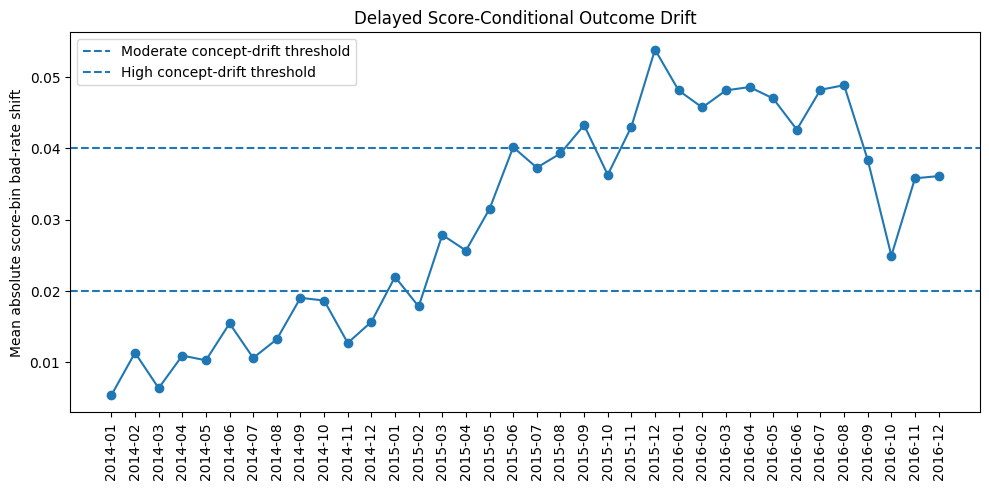

In [64]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_concept_drift["monitor_month"],monthly_concept_drift["score_bin_mean_absolute_shift"], marker="o")
plt.axhline(concept_moderate_threshold, linestyle="--", label="Moderate concept-drift threshold")
plt.axhline(concept_high_threshold, linestyle="--", label="High concept-drift threshold")
plt.xticks(rotation=90)
plt.ylabel("Mean absolute score-bin bad-rate shift")
plt.title("Delayed Score-Conditional Outcome Drift")
plt.legend()
plt.tight_layout()
plt.show()

Score-conditional outcome drift triggered in 23 of the 36 cohorts once labels became available:
11 were moderate and 12 high. The largest weighted shift was 0.0539.
All triggered cohorts were classified as largely target-prior shift. Meaning the change was broadly
in the same direction across score bands rather than concentrated in particular parts of the score
range.

## 7. Delayed Performance Monitoring

This is the strongest evidence in the notebook, and the slowest to arrive. Unlike feature and prediction drift, it needs mature labels, so the same five-month delay applies.

Monthly performance is compared with the November–December 2013 baseline. Calibration gap and Brier score are treated as the primary metrics because the project is about probability reliability, with ROC AUC and log loss alongside them.

In [65]:
# Return missing when a month has one outcome class
def safe_roc_auc(y_true, y_score):
    if pd.Series(y_true).nunique() < 2:
        return np.nan

    return roc_auc_score(y_true, y_score)

In [66]:
# Return missing when average precision cannot be calculated
def safe_average_precision(y_true, y_score):
    if pd.Series(y_true).nunique() < 2:
        return np.nan

    return average_precision_score(y_true, y_score)

In [67]:
# Clip probabilities before calculating log loss
def safe_log_loss(y_true, y_score):
    y_score = np.clip(np.asarray(y_score, dtype=float), 1e-6, 1 - 1e-6)

    return log_loss(y_true, y_score, labels=[0, 1])

In [68]:
# Calculate performance metrics for one monitoring month
def calculate_monthly_performance(month_df, target_col, prediction_col):
    y_true = month_df[target_col]
    y_score = month_df[prediction_col]

    actual_bad_loan_rate = y_true.mean()
    mean_predicted_probability = y_score.mean()

    return {"rows": len(month_df),
            "actual_bad_loan_rate": actual_bad_loan_rate,
            "mean_predicted_probability": mean_predicted_probability,
            "calibration_gap": actual_bad_loan_rate - mean_predicted_probability,
            "absolute_calibration_gap": abs(actual_bad_loan_rate - mean_predicted_probability),
            "roc_auc": safe_roc_auc(y_true, y_score),
            "average_precision": safe_average_precision(y_true, y_score),
            "log_loss": safe_log_loss(y_true, y_score),
            "brier_score": brier_score_loss(y_true, y_score)}

In [69]:
# Monthly performance with delayed label availability
label_delay_months = 5

if "monitor_month" not in simulation_df.columns:
    simulation_df["monitor_month"] = pd.to_datetime(simulation_df["issue_d"]).dt.to_period("M").astype(str)

In [70]:
# Calculate performance for each monitoring month
monthly_performance_rows = []

for month, month_df in simulation_df.groupby("monitor_month"):
    performance = calculate_monthly_performance(month_df, target_col, prediction_col)
    label_available_month = (pd.Period(month, freq="M") + label_delay_months).strftime("%Y-%m")

    performance.update({"monitor_month": month,
                        "label_available_month": label_available_month,
                        "label_delay_months": label_delay_months})

    monthly_performance_rows.append(performance)

monthly_delayed_performance = pd.DataFrame(monthly_performance_rows)

In [71]:
# Order the monthly performance columns
monthly_delayed_performance = monthly_delayed_performance[["monitor_month", "label_available_month", "label_delay_months", "rows",
                                                           "actual_bad_loan_rate", "mean_predicted_probability", "calibration_gap",
                                                           "absolute_calibration_gap", "roc_auc", "average_precision","log_loss", "brier_score"]].sort_values("monitor_month").reset_index(drop=True)

display(monthly_delayed_performance.head(12).round(4))
display(monthly_delayed_performance.iloc[12:24].round(4))
display(monthly_delayed_performance.tail(12).round(4))

,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,absolute_calibration_gap,roc_auc,average_precision,log_loss,brier_score
0,2014-01,2014-06,5,15628,0.1588,0.1544,0.0045,0.0045,0.6928,0.2897,0.4066,0.1251
1,2014-02,2014-07,5,15269,0.1658,0.1593,0.0065,0.0065,0.6912,0.2971,0.4171,0.1294
2,2014-03,2014-08,5,16513,0.1674,0.1661,0.0013,0.0013,0.6995,0.3106,0.4158,0.1294
3,2014-04,2014-09,5,19071,0.1756,0.1640,0.0116,0.0116,0.6915,0.3099,0.4316,0.1352
4,2014-05,2014-10,5,19099,0.1756,0.1658,0.0098,0.0098,0.6954,0.3112,0.4299,0.1349
5,2014-06,2014-11,5,17179,0.1838,0.1693,0.0145,0.0145,0.6998,0.3338,0.4391,0.1387
6,2014-07,2014-12,5,29306,0.1790,0.1702,0.0089,0.0089,0.6958,0.3242,0.4340,0.1364
7,2014-08,2015-01,5,18814,0.1804,0.1683,0.0121,0.0121,0.7110,0.3354,0.4301,0.1356
8,2014-09,2015-02,5,10606,0.1800,0.1630,0.0170,0.0170,0.7060,0.3334,0.4319,0.1361
9,2014-10,2015-03,5,38781,0.1867,0.1678,0.0189,0.0189,0.7013,0.3368,0.4435,0.1404


,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,absolute_calibration_gap,roc_auc,average_precision,log_loss,brier_score
12,2015-01,2015-06,5,35080,0.1897,0.1674,0.0223,0.0223,0.7017,0.3379,0.4476,0.1423
13,2015-02,2015-07,5,23734,0.1832,0.1652,0.0179,0.0179,0.7029,0.3381,0.4378,0.1380
14,2015-03,2015-08,5,25361,0.1962,0.1681,0.0281,0.0281,0.6981,0.3458,0.4587,0.1463
15,2015-04,2015-09,5,35259,0.1926,0.1668,0.0258,0.0258,0.6985,0.3433,0.4534,0.1441
16,2015-05,2015-10,5,31174,0.1972,0.1660,0.0312,0.0312,0.7055,0.3582,0.4573,0.1459
17,2015-06,2015-11,5,27001,0.2055,0.1655,0.0401,0.0401,0.7186,0.3889,0.4633,0.1487
18,2015-07,2015-12,5,43415,0.2006,0.1630,0.0376,0.0376,0.7217,0.3843,0.4554,0.1458
19,2015-08,2016-01,5,33552,0.1995,0.1594,0.0401,0.0401,0.7296,0.3918,0.4515,0.1443
20,2015-09,2016-02,5,26687,0.2053,0.1620,0.0434,0.0434,0.7228,0.3886,0.4623,0.1487
21,2015-10,2016-03,5,45444,0.1914,0.1537,0.0376,0.0376,0.7225,0.3695,0.4439,0.1413


,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,absolute_calibration_gap,roc_auc,average_precision,log_loss,brier_score
24,2016-01,2016-06,5,30161,0.1974,0.1482,0.0491,0.0491,0.7366,0.4012,0.4487,0.1431
25,2016-02,2016-07,5,36788,0.1983,0.1510,0.0473,0.0473,0.7180,0.3844,0.4577,0.1457
26,2016-03,2016-08,5,57558,0.2020,0.1526,0.0494,0.0494,0.7202,0.3774,0.4622,0.1482
27,2016-04,2016-09,5,34164,0.1994,0.1487,0.0507,0.0507,0.7153,0.3749,0.4617,0.1474
28,2016-05,2016-10,5,26488,0.1996,0.1507,0.0489,0.0489,0.7077,0.3719,0.4642,0.1480
29,2016-06,2016-11,5,30582,0.1876,0.1423,0.0453,0.0453,0.7173,0.3693,0.4442,0.1402
30,2016-07,2016-12,5,32050,0.2085,0.1578,0.0507,0.0507,0.7009,0.3822,0.4780,0.1534
31,2016-08,2017-01,5,33641,0.2054,0.1539,0.0515,0.0515,0.6997,0.3726,0.4759,0.1523
32,2016-09,2017-02,5,26171,0.1959,0.1550,0.0410,0.0410,0.6996,0.3674,0.4592,0.1461
33,2016-10,2017-03,5,30305,0.1761,0.1480,0.0281,0.0281,0.6916,0.3191,0.4348,0.1358


In [72]:
# Use the calibration row as the delayed performance baseline
performance_baseline = concept_drift_baseline.copy()

if "dataset" in performance_baseline.columns:
    performance_baseline = performance_baseline[
        performance_baseline["dataset"] == "calibration"
    ].copy()

if performance_baseline.shape[0] != 1:
    raise ValueError("Expected one calibration baseline row.")

performance_baseline = performance_baseline.iloc[0]

In [73]:
# Extract the baseline performance values
baseline_actual_bad_rate = float(performance_baseline["actual_bad_loan_rate"])
baseline_mean_prediction = float(performance_baseline["mean_predicted_probability"])
baseline_calibration_gap = float(performance_baseline["calibration_gap"])
baseline_absolute_calibration_gap = abs(baseline_calibration_gap)
baseline_auc = float(performance_baseline["roc_auc"])
baseline_average_precision = float(performance_baseline["average_precision"])
baseline_log_loss = float(performance_baseline["log_loss"])
baseline_brier_score = float(performance_baseline["brier_score"])

print("Baseline actual bad-loan rate:", round(baseline_actual_bad_rate, 4))
print("Baseline mean prediction:", round(baseline_mean_prediction, 4))
print("Baseline calibration gap:", round(baseline_calibration_gap, 4))
print("Baseline absolute calibration gap:", round(baseline_absolute_calibration_gap, 4))
print("Baseline ROC AUC:", round(baseline_auc, 4))
print("Baseline Brier score:", round(baseline_brier_score, 4))

Baseline actual bad-loan rate: 0.1536
Baseline mean prediction: 0.1511
Baseline calibration gap: 0.0025
Baseline absolute calibration gap: 0.0025
Baseline ROC AUC: 0.699
Baseline Brier score: 0.1216


In [74]:
# Express every metric as a change from the baseline
monthly_delayed_performance["bad_rate_change"] = (monthly_delayed_performance["actual_bad_loan_rate"] -baseline_actual_bad_rate)

monthly_delayed_performance["calibration_gap_change"] = (monthly_delayed_performance["calibration_gap"] - baseline_calibration_gap)

monthly_delayed_performance["absolute_calibration_gap_change"] = (monthly_delayed_performance["absolute_calibration_gap"] -
                                                                  baseline_absolute_calibration_gap)

monthly_delayed_performance["auc_change"] = monthly_delayed_performance["roc_auc"] - baseline_auc
monthly_delayed_performance["auc_drop"] = baseline_auc - monthly_delayed_performance["roc_auc"]

monthly_delayed_performance["average_precision_change"] = (monthly_delayed_performance["average_precision"] - baseline_average_precision)

monthly_delayed_performance["log_loss_change"] = monthly_delayed_performance["log_loss"] - baseline_log_loss
monthly_delayed_performance["brier_score_change"] = (monthly_delayed_performance["brier_score"] - baseline_brier_score)

display(monthly_delayed_performance.head(12).round(4))
display(monthly_delayed_performance.iloc[12:24].round(4))
display(monthly_delayed_performance.tail(12).round(4))

,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,absolute_calibration_gap,roc_auc,average_precision,log_loss,brier_score,bad_rate_change,calibration_gap_change,absolute_calibration_gap_change,auc_change,auc_drop,average_precision_change,log_loss_change,brier_score_change
0,2014-01,2014-06,5,15628,0.1588,0.1544,0.0045,0.0045,0.6928,0.2897,0.4066,0.1251,0.0052,0.0019,0.0019,-0.0062,0.0062,0.0084,0.0102,0.0035
1,2014-02,2014-07,5,15269,0.1658,0.1593,0.0065,0.0065,0.6912,0.2971,0.4171,0.1294,0.0122,0.0040,0.0040,-0.0078,0.0078,0.0159,0.0207,0.0078
2,2014-03,2014-08,5,16513,0.1674,0.1661,0.0013,0.0013,0.6995,0.3106,0.4158,0.1294,0.0138,-0.0012,-0.0012,0.0004,-0.0004,0.0294,0.0194,0.0077
3,2014-04,2014-09,5,19071,0.1756,0.1640,0.0116,0.0116,0.6915,0.3099,0.4316,0.1352,0.0220,0.0091,0.0091,-0.0075,0.0075,0.0287,0.0352,0.0135
4,2014-05,2014-10,5,19099,0.1756,0.1658,0.0098,0.0098,0.6954,0.3112,0.4299,0.1349,0.0220,0.0073,0.0073,-0.0037,0.0037,0.0299,0.0334,0.0132
5,2014-06,2014-11,5,17179,0.1838,0.1693,0.0145,0.0145,0.6998,0.3338,0.4391,0.1387,0.0302,0.0120,0.0120,0.0008,-0.0008,0.0526,0.0427,0.0171
6,2014-07,2014-12,5,29306,0.1790,0.1702,0.0089,0.0089,0.6958,0.3242,0.4340,0.1364,0.0254,0.0063,0.0063,-0.0033,0.0033,0.0430,0.0376,0.0148
7,2014-08,2015-01,5,18814,0.1804,0.1683,0.0121,0.0121,0.7110,0.3354,0.4301,0.1356,0.0268,0.0095,0.0095,0.0119,-0.0119,0.0542,0.0337,0.0140
8,2014-09,2015-02,5,10606,0.1800,0.1630,0.0170,0.0170,0.7060,0.3334,0.4319,0.1361,0.0264,0.0145,0.0145,0.0069,-0.0069,0.0522,0.0355,0.0145
9,2014-10,2015-03,5,38781,0.1867,0.1678,0.0189,0.0189,0.7013,0.3368,0.4435,0.1404,0.0331,0.0164,0.0164,0.0023,-0.0023,0.0556,0.0471,0.0187


,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,absolute_calibration_gap,roc_auc,average_precision,log_loss,brier_score,bad_rate_change,calibration_gap_change,absolute_calibration_gap_change,auc_change,auc_drop,average_precision_change,log_loss_change,brier_score_change
12,2015-01,2015-06,5,35080,0.1897,0.1674,0.0223,0.0223,0.7017,0.3379,0.4476,0.1423,0.0361,0.0198,0.0198,0.0027,-0.0027,0.0567,0.0512,0.0206
13,2015-02,2015-07,5,23734,0.1832,0.1652,0.0179,0.0179,0.7029,0.3381,0.4378,0.1380,0.0296,0.0154,0.0154,0.0038,-0.0038,0.0569,0.0414,0.0163
14,2015-03,2015-08,5,25361,0.1962,0.1681,0.0281,0.0281,0.6981,0.3458,0.4587,0.1463,0.0426,0.0255,0.0255,-0.0009,0.0009,0.0646,0.0623,0.0247
15,2015-04,2015-09,5,35259,0.1926,0.1668,0.0258,0.0258,0.6985,0.3433,0.4534,0.1441,0.0390,0.0233,0.0233,-0.0005,0.0005,0.0621,0.0570,0.0225
16,2015-05,2015-10,5,31174,0.1972,0.1660,0.0312,0.0312,0.7055,0.3582,0.4573,0.1459,0.0436,0.0287,0.0287,0.0064,-0.0064,0.0769,0.0608,0.0242
17,2015-06,2015-11,5,27001,0.2055,0.1655,0.0401,0.0401,0.7186,0.3889,0.4633,0.1487,0.0519,0.0375,0.0375,0.0195,-0.0195,0.1077,0.0669,0.0271
18,2015-07,2015-12,5,43415,0.2006,0.1630,0.0376,0.0376,0.7217,0.3843,0.4554,0.1458,0.0470,0.0351,0.0351,0.0227,-0.0227,0.1031,0.0590,0.0242
19,2015-08,2016-01,5,33552,0.1995,0.1594,0.0401,0.0401,0.7296,0.3918,0.4515,0.1443,0.0459,0.0375,0.0375,0.0306,-0.0306,0.1106,0.0551,0.0227
20,2015-09,2016-02,5,26687,0.2053,0.1620,0.0434,0.0434,0.7228,0.3886,0.4623,0.1487,0.0517,0.0408,0.0408,0.0237,-0.0237,0.1074,0.0658,0.0270
21,2015-10,2016-03,5,45444,0.1914,0.1537,0.0376,0.0376,0.7225,0.3695,0.4439,0.1413,0.0378,0.0351,0.0351,0.0234,-0.0234,0.0882,0.0475,0.0196


,monitor_month,label_available_month,label_delay_months,rows,actual_bad_loan_rate,mean_predicted_probability,calibration_gap,absolute_calibration_gap,roc_auc,average_precision,log_loss,brier_score,bad_rate_change,calibration_gap_change,absolute_calibration_gap_change,auc_change,auc_drop,average_precision_change,log_loss_change,brier_score_change
24,2016-01,2016-06,5,30161,0.1974,0.1482,0.0491,0.0491,0.7366,0.4012,0.4487,0.1431,0.0438,0.0466,0.0466,0.0375,-0.0375,0.1200,0.0523,0.0215
25,2016-02,2016-07,5,36788,0.1983,0.1510,0.0473,0.0473,0.7180,0.3844,0.4577,0.1457,0.0447,0.0447,0.0447,0.0190,-0.0190,0.1032,0.0612,0.0241
26,2016-03,2016-08,5,57558,0.2020,0.1526,0.0494,0.0494,0.7202,0.3774,0.4622,0.1482,0.0484,0.0469,0.0469,0.0211,-0.0211,0.0962,0.0658,0.0266
27,2016-04,2016-09,5,34164,0.1994,0.1487,0.0507,0.0507,0.7153,0.3749,0.4617,0.1474,0.0458,0.0482,0.0482,0.0163,-0.0163,0.0937,0.0652,0.0257
28,2016-05,2016-10,5,26488,0.1996,0.1507,0.0489,0.0489,0.7077,0.3719,0.4642,0.1480,0.0460,0.0464,0.0464,0.0087,-0.0087,0.0907,0.0678,0.0264
29,2016-06,2016-11,5,30582,0.1876,0.1423,0.0453,0.0453,0.7173,0.3693,0.4442,0.1402,0.0340,0.0428,0.0428,0.0183,-0.0183,0.0881,0.0477,0.0185
30,2016-07,2016-12,5,32050,0.2085,0.1578,0.0507,0.0507,0.7009,0.3822,0.4780,0.1534,0.0549,0.0481,0.0481,0.0018,-0.0018,0.1009,0.0816,0.0318
31,2016-08,2017-01,5,33641,0.2054,0.1539,0.0515,0.0515,0.6997,0.3726,0.4759,0.1523,0.0518,0.0490,0.0490,0.0007,-0.0007,0.0914,0.0795,0.0306
32,2016-09,2017-02,5,26171,0.1959,0.1550,0.0410,0.0410,0.6996,0.3674,0.4592,0.1461,0.0423,0.0385,0.0385,0.0006,-0.0006,0.0861,0.0628,0.0244
33,2016-10,2017-03,5,30305,0.1761,0.1480,0.0281,0.0281,0.6916,0.3191,0.4348,0.1358,0.0225,0.0256,0.0256,-0.0074,0.0074,0.0378,0.0384,0.0141


Delayed performance drift is classified against the baseline using these operational thresholds.

Moderate if any of:

- absolute calibration gap ≥ 0.03
- Brier score increase ≥ 0.015
- ROC AUC drop ≥ 0.05

High if any of:

- absolute calibration gap ≥ 0.05
- Brier score increase ≥ 0.03
- ROC AUC drop ≥ 0.10

Splitting the metrics this way keeps a reliability problem distinct from a ranking problem. In this project the deterioration was expected to show up through calibration and Brier rather than a collapse in ROC AUC.

In [75]:
# Set operational performance thresholds
calibration_gap_moderate_threshold = 0.03
calibration_gap_high_threshold = 0.05

brier_moderate_threshold = 0.015
brier_high_threshold = 0.030

auc_drop_moderate_threshold = 0.05
auc_drop_high_threshold = 0.10

monthly_delayed_performance["calibration_gap_moderate_flag"] = (monthly_delayed_performance["absolute_calibration_gap"] >=
                                                                calibration_gap_moderate_threshold)

monthly_delayed_performance["calibration_gap_high_flag"] = (monthly_delayed_performance["absolute_calibration_gap"] >=
                                                            calibration_gap_high_threshold)

monthly_delayed_performance["brier_moderate_flag"] = (monthly_delayed_performance["brier_score_change"] >= brier_moderate_threshold)

monthly_delayed_performance["brier_high_flag"] = (monthly_delayed_performance["brier_score_change"] >= brier_high_threshold)

monthly_delayed_performance["auc_moderate_flag"] = monthly_delayed_performance["auc_drop"] >= auc_drop_moderate_threshold
monthly_delayed_performance["auc_high_flag"] = monthly_delayed_performance["auc_drop"] >= auc_drop_high_threshold

In [76]:
# Classify delayed performance drift
def classify_delayed_performance_drift(row):
    if row["calibration_gap_high_flag"] or row["brier_high_flag"] or row["auc_high_flag"]:
        return "high"
    elif row["calibration_gap_moderate_flag"] or row["brier_moderate_flag"] or row["auc_moderate_flag"]:
        return "moderate"
    else:
        return "low"

In [77]:
# Record which metrics caused the drift flag
def explain_performance_drift_reason(row):
    reasons = []

    if row["calibration_gap_high_flag"]:
        reasons.append("high calibration gap")
    elif row["calibration_gap_moderate_flag"]:
        reasons.append("moderate calibration gap")

    if row["brier_high_flag"]:
        reasons.append("high Brier increase")
    elif row["brier_moderate_flag"]:
        reasons.append("moderate Brier increase")

    if row["auc_high_flag"]:
        reasons.append("high ROC AUC drop")
    elif row["auc_moderate_flag"]:
        reasons.append("moderate ROC AUC drop")

    if len(reasons) == 0:
        return "no delayed performance drift"

    return "; ".join(reasons)

In [78]:
# Apply the delayed performance rules
monthly_delayed_performance["delayed_performance_drift_level"] = monthly_delayed_performance.apply(classify_delayed_performance_drift, axis=1)

monthly_delayed_performance["delayed_performance_trigger"] = monthly_delayed_performance["delayed_performance_drift_level"].isin(["moderate", "high"])

monthly_delayed_performance["delayed_performance_reason"] = monthly_delayed_performance.apply(explain_performance_drift_reason, axis=1)

In [79]:
# Headline delayed performance numbers
delayed_performance_summary = pd.DataFrame([{"months": monthly_delayed_performance.shape[0],
                                             "triggered_months": monthly_delayed_performance["delayed_performance_trigger"].sum(),
                                             "low_months": (monthly_delayed_performance["delayed_performance_drift_level"] == "low").sum(),
                                             "moderate_months": (monthly_delayed_performance["delayed_performance_drift_level"] == "moderate").sum(),
                                             "high_months": (monthly_delayed_performance["delayed_performance_drift_level"] == "high").sum(),
                                             "max_actual_bad_loan_rate": monthly_delayed_performance["actual_bad_loan_rate"].max(),
                                             "max_calibration_gap": monthly_delayed_performance["calibration_gap"].max(),
                                             "max_absolute_calibration_gap": monthly_delayed_performance["absolute_calibration_gap"].max(),
                                             "max_brier_score": monthly_delayed_performance["brier_score"].max(),
                                             "max_brier_score_change": monthly_delayed_performance["brier_score_change"].max(),
                                             "min_roc_auc": monthly_delayed_performance["roc_auc"].min(),
                                             "max_auc_drop": monthly_delayed_performance["auc_drop"].max()}])

display(delayed_performance_summary.round(4))

delayed_performance_level_counts = (monthly_delayed_performance[
    ["delayed_performance_drift_level", "delayed_performance_trigger"]]
    .value_counts()
    .reset_index(name="months"))

display(delayed_performance_level_counts)

delayed_performance_reason_counts = (monthly_delayed_performance[["delayed_performance_reason"]].value_counts().reset_index(name="months"))

display(delayed_performance_reason_counts)

,months,triggered_months,low_months,moderate_months,high_months,max_actual_bad_loan_rate,max_calibration_gap,max_absolute_calibration_gap,max_brier_score,max_brier_score_change,min_roc_auc,max_auc_drop
0,36,26,10,22,4,0.2115,0.0548,0.0548,0.1534,0.0318,0.6912,0.0078


,delayed_performance_drift_level,delayed_performance_trigger,months
0,moderate,True,22
1,low,False,10
2,high,True,4


,delayed_performance_reason,months
0,moderate calibration gap; moderate Brier increase,15
1,no delayed performance drift,10
2,moderate Brier increase,7
3,high calibration gap; high Brier increase,3
4,high calibration gap; moderate Brier increase,1


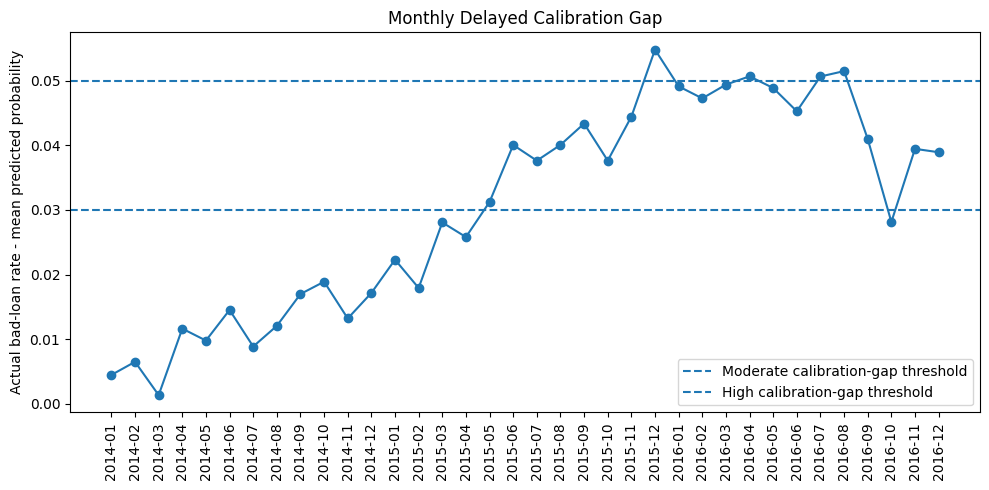

In [80]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_delayed_performance["monitor_month"], monthly_delayed_performance["calibration_gap"], marker="o")
plt.axhline(0.03, linestyle="--", label="Moderate calibration-gap threshold")
plt.axhline(0.05, linestyle="--", label="High calibration-gap threshold")
plt.xticks(rotation=90)
plt.ylabel("Actual bad-loan rate - mean predicted probability")
plt.title("Monthly Delayed Calibration Gap")
plt.legend()
plt.tight_layout()
plt.show()

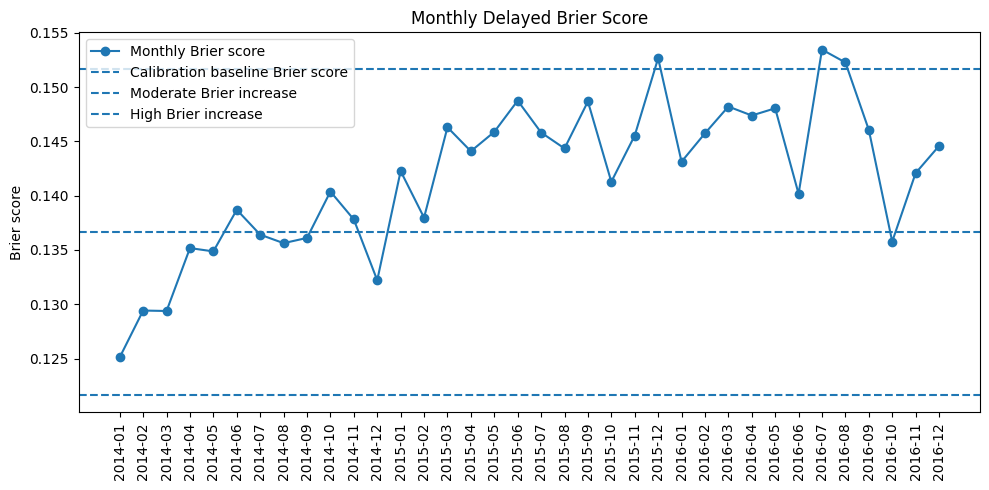

In [81]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_delayed_performance["monitor_month"],monthly_delayed_performance["brier_score"],
         marker="o", label="Monthly Brier score")
plt.axhline(baseline_brier_score, linestyle="--", label="Calibration baseline Brier score")
plt.axhline(baseline_brier_score + 0.015, linestyle="--", label="Moderate Brier increase")
plt.axhline(baseline_brier_score + 0.03, linestyle="--", label="High Brier increase")
plt.xticks(rotation=90)
plt.ylabel("Brier score")
plt.title("Monthly Delayed Brier Score")
plt.legend()
plt.tight_layout()
plt.show()

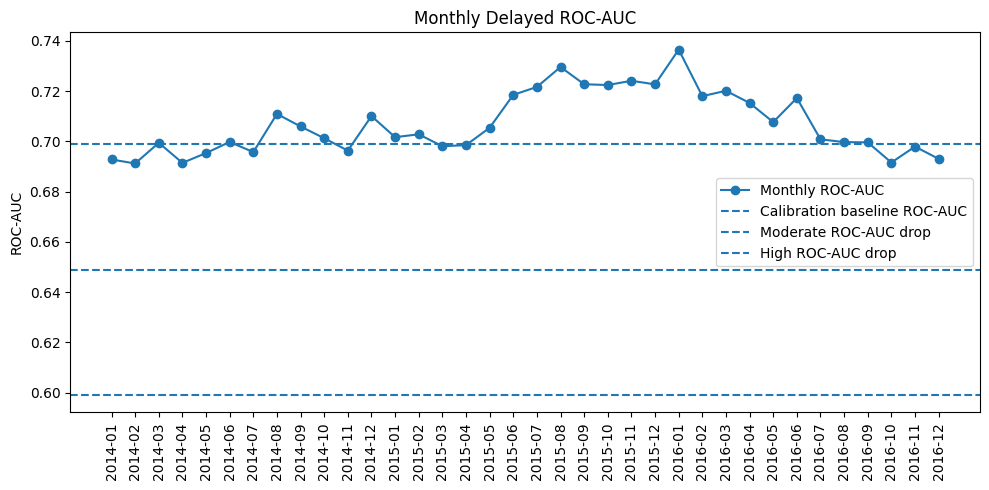

In [82]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_delayed_performance["monitor_month"], monthly_delayed_performance["roc_auc"],
         marker="o", label="Monthly ROC-AUC")
plt.axhline(baseline_auc, linestyle="--", label="Calibration baseline ROC-AUC")
plt.axhline(baseline_auc - 0.05, linestyle="--", label="Moderate ROC-AUC drop")
plt.axhline(baseline_auc - 0.10, linestyle="--", label="High ROC-AUC drop")
plt.xticks(rotation=90)
plt.ylabel("ROC-AUC")
plt.title("Monthly Delayed ROC-AUC")
plt.legend()
plt.tight_layout()
plt.show()

Delayed performance drift appeared in 26 of the 36 cohorts once labels became available, with 22 moderate and 4 high cases. The main deterioration was in calibration and Brier score, while ROC-AUC stayed close to its baseline and never crossed the ranking-deterioration threshold. This suggests the problem was mainly one of probability reliability rather than ranking. The model still separated higher and lower risk loans reasonably okay, but its predicted probabilities are too low for the outcomes observed.


## 7b. Monthly Data-Quality Monitoring

Monthly data quality is checked for unseen categorical levels and changes in missingness.
These signals are available immediately but are used only as supporting evidence in the policy.

In [83]:
# Set the data-quality threshold
data_quality_missing_rate_threshold = 0.001

# Keep category levels seen in the reference period
reference_category_levels = {feature: set(prepare_discrete_values(feature_reference_df[feature]).unique())
                             for feature in monitoring_categorical_cols}

In [84]:
# Check unseen categories and missingness each month
data_quality_rows = []

for month, month_df in simulation_df.groupby("monitor_month"):
    unseen_category_count = 0
    unseen_category_detail = []

    for feature in monitoring_categorical_cols:
        current_levels = set(prepare_discrete_values(month_df[feature]).unique())
        unseen_levels = current_levels - reference_category_levels[feature]

        if len(unseen_levels) > 0:
            unseen_category_count += len(unseen_levels)
            unseen_category_detail.append(f"{feature}: {sorted(unseen_levels)}")

    mean_feature_missing_rate = month_df[monitoring_feature_cols].isna().mean().mean()

    data_quality_rows.append({"monitor_month": month,
                              "rows": len(month_df),
                              "unseen_category_count": unseen_category_count,
                              "unseen_category_detail": "; ".join(unseen_category_detail),
                              "mean_feature_missing_rate": mean_feature_missing_rate})

monthly_data_quality = pd.DataFrame(data_quality_rows)

In [85]:
# Use data quality as a supporting governance signal
monthly_data_quality["data_quality_flag"] = ((monthly_data_quality["unseen_category_count"] > 0) |
                                             (monthly_data_quality["mean_feature_missing_rate"] >
                                              data_quality_missing_rate_threshold))

print("Months with a data-quality flag:", int(monthly_data_quality["data_quality_flag"].sum()), "of", monthly_data_quality.shape[0])

display(monthly_data_quality.head(12))
display(monthly_data_quality[monthly_data_quality["data_quality_flag"]])

Months with a data-quality flag: 10 of 36


,monitor_month,rows,unseen_category_count,unseen_category_detail,mean_feature_missing_rate,data_quality_flag
0,2014-01,15628,0,,0.0,False
1,2014-02,15269,0,,0.0,False
2,2014-03,16513,0,,0.0,False
3,2014-04,19071,0,,0.0,False
4,2014-05,19099,0,,0.0,False
5,2014-06,17179,0,,0.0,False
6,2014-07,29306,0,,0.0,False
7,2014-08,18814,0,,0.0,False
8,2014-09,10606,1,home_ownership: ['ANY'],0.0,True
9,2014-10,38781,0,,0.0,False


,monitor_month,rows,unseen_category_count,unseen_category_detail,mean_feature_missing_rate,data_quality_flag
8,2014-09,10606,1,home_ownership: ['ANY'],0.0,True
15,2015-04,35259,1,purpose: ['educational'],0.0,True
18,2015-07,43415,1,home_ownership: ['ANY'],0.0,True
23,2015-12,41307,1,home_ownership: ['ANY'],0.0,True
30,2016-07,32050,1,home_ownership: ['ANY'],0.0,True
31,2016-08,33641,1,home_ownership: ['ANY'],0.0,True
32,2016-09,26171,1,home_ownership: ['ANY'],0.0,True
33,2016-10,30305,1,home_ownership: ['ANY'],0.0,True
34,2016-11,31767,1,home_ownership: ['ANY'],0.0,True
35,2016-12,33429,1,home_ownership: ['ANY'],0.0,True


Data-quality flags appeared in 10 of the 36 months, all due to categorical levels that were not
present in the 2013 reference data. No missingness-based flags were observed.

## 7c. Making the Label Delay Binding for the Retraining Policy


The five-month delay affects when outcome-based evidence can be used, rather than the value of
the metric itself. Each delayed signal is therefore linked to its `decision_month`, five months
after the cohort was scored.
Feature drift, prediction drift and data quality remain available immediately, while target,
score-conditional and performance evidence only become available after the simulated delay.

The five-month delay is a simulation assumption rather than an estimate of actual Lending Club
outcome latency. Its purpose is to enforce delayed evidence consistently throughout the replay.

In [86]:
# Make delayed signals usable only when their labels arrive
delayed_monitoring_tables = {"monthly_target_drift": monthly_target_drift,
                             "monthly_concept_drift": monthly_concept_drift,
                             "monthly_delayed_performance": monthly_delayed_performance}

for table_name, table in delayed_monitoring_tables.items():
    if "label_available_month" not in table.columns:
        raise ValueError(f"{table_name} is missing label_available_month.")

    # Notebook 5 joins delayed signals on this month
    table["decision_month"] = table["label_available_month"]
    table["delayed_signal_usable"] = True

In [87]:
# Check when delayed signals become available
decision_month_check = monthly_delayed_performance[["monitor_month", "label_available_month", "label_delay_months",
                                                    "decision_month", "delayed_signal_usable"]].head(12)

print("Label delay applied (months):", label_delay_months)
print("Delayed tables updated:", list(delayed_monitoring_tables.keys()))

display(decision_month_check)

Label delay applied (months): 5
Delayed tables updated: ['monthly_target_drift', 'monthly_concept_drift', 'monthly_delayed_performance']


,monitor_month,label_available_month,label_delay_months,decision_month,delayed_signal_usable
0,2014-01,2014-06,5,2014-06,True
1,2014-02,2014-07,5,2014-07,True
2,2014-03,2014-08,5,2014-08,True
3,2014-04,2014-09,5,2014-09,True
4,2014-05,2014-10,5,2014-10,True
5,2014-06,2014-11,5,2014-11,True
6,2014-07,2014-12,5,2014-12,True
7,2014-08,2015-01,5,2015-01,True
8,2014-09,2015-02,5,2015-02,True
9,2014-10,2015-03,5,2015-03,True


## 8. Saving Monitoring Outputs for the Retraining Policy Notebook

These tables are the input to Notebook 05. The threshold metadata is saved with them so the policy notebook reuses the same assumptions rather than redeclaring them.

In [88]:
# Output directory for the monitoring tables
os.makedirs(monitoring_dir, exist_ok=True)

print("Monitoring output directory:", monitoring_dir)

Monitoring output directory: ../artifacts/monitoring


In [89]:
# Save monthly cohort counts and feature-drift monitoring outputs
monthly_counts.to_csv(f"{monitoring_dir}/monthly_counts.csv", index=False)

feature_drift_long.to_csv(f"{monitoring_dir}/monthly_feature_drift_long.csv", index=False)
monthly_feature_drift_summary.to_csv(f"{monitoring_dir}/monthly_feature_drift_summary.csv", index=False)
monthly_feature_drift_summary_excl_policy.to_csv(
    f"{monitoring_dir}/monthly_feature_drift_summary_excl_policy.csv", index=False)
top_drifting_features.to_csv(f"{monitoring_dir}/top_drifting_features.csv", index=False)

print("Saved monthly counts and feature-drift outputs.")

Saved monthly counts and feature-drift outputs.


In [90]:
# Save prediction-drift monitoring outputs
monthly_prediction_drift.to_csv(f"{monitoring_dir}/monthly_prediction_drift.csv", index=False)
yearly_prediction_drift_summary.to_csv(f"{monitoring_dir}/yearly_prediction_drift_summary.csv", index=False)

print("Saved prediction-drift outputs.")

Saved prediction-drift outputs.


In [91]:
# Save delayed target, score-conditional outcome, and performance monitoring outputs
monthly_target_drift.to_csv(f"{monitoring_dir}/monthly_target_drift.csv", index=False)
target_drift_check.to_csv(f"{monitoring_dir}/target_drift_check.csv", index=False)

monthly_concept_drift.to_csv(f"{monitoring_dir}/monthly_score_conditional_outcome_drift.csv", index=False)
concept_null_distribution.to_csv(f"{monitoring_dir}/concept_drift_null_distribution.csv", index=False)
concept_threshold_check.to_csv(f"{monitoring_dir}/concept_threshold_check.csv", index=False)
concept_drift_summary.to_csv(f"{monitoring_dir}/concept_drift_summary.csv", index=False)

monthly_delayed_performance.to_csv(f"{monitoring_dir}/monthly_delayed_performance.csv", index=False)
delayed_performance_summary.to_csv(f"{monitoring_dir}/delayed_performance_summary.csv", index=False)

monthly_data_quality.to_csv(f"{monitoring_dir}/monthly_data_quality.csv", index=False)

print("Saved delayed outcome-aware monitoring outputs.")
print("Saved monthly data-quality outputs.")

Saved delayed outcome-aware monitoring outputs.
Saved monthly data-quality outputs.


In [92]:
# Save monitoring settings for Notebook 5
monitoring_metadata = {"label_delay_months": int(label_delay_months),
                       "label_delay_note": ("Simulation device, not true label latency. The target uses terminal loan statuses "
                                            "(Fully Paid, Charged Off, Default), so realistic latency would approach the 36- or "
                                            "60-month loan term. Delayed signals are usable only from decision_month onwards."),
                       "prediction_jsd_moderate_band": float(prediction_jsd_moderate_band),
                       "prediction_jsd_high_band": float(prediction_jsd_high_band),
                       "target_moderate_threshold": float(target_moderate_threshold),
                       "target_high_threshold": float(target_high_threshold),
                       "concept_moderate_threshold": float(concept_moderate_threshold),
                       "concept_high_threshold": float(concept_high_threshold),
                       "concept_localisation_threshold": float(concept_localisation_threshold),
                       "calibration_gap_moderate_threshold": float(calibration_gap_moderate_threshold),
                       "calibration_gap_high_threshold": float(calibration_gap_high_threshold),
                       "brier_moderate_threshold": float(brier_moderate_threshold),
                       "brier_high_threshold": float(brier_high_threshold),
                       "auc_drop_moderate_threshold": float(auc_drop_moderate_threshold),
                       "auc_drop_high_threshold": float(auc_drop_high_threshold),
                       "psi_moderate_band": 0.10,
                       "psi_high_band": 0.25,
                       "platform_policy_features": platform_policy_features,
                       "data_quality_missing_rate_threshold": float(data_quality_missing_rate_threshold),
                       "signal_roles": {"feature_drift": "early_warning_only",
                                        "prediction_drift": "early_warning_only",
                                        "data_quality": "governance_corroborating_only",
                                        "target_drift": "corroborating_only",
                                        "score_conditional_outcome_drift": "strong_delayed_evidence",
                                        "delayed_performance_drift": "strongest_delayed_evidence"}}

with open(f"{monitoring_dir}/monitoring_threshold_metadata.json", "w") as f:
    json.dump(monitoring_metadata, f, indent=4)

print("Saved monitoring threshold metadata.")
print("Notebook 04 monitoring outputs saved successfully.")

Saved monitoring threshold metadata.
Notebook 04 monitoring outputs saved successfully.
